# Vize sunumu: veri akışı ve keşifsel analiz

**Ev doluluk tespiti (HPDmobile)**: görüntü + ses + ortam sensörü → 10 sn pencerede 0 / 1 / 2+ kişi.

Bu notebook sunumda canlı açılır. Akış: **ham dosya → eşleştirme → temizleme → analiz → modele hazır örnek**.
Her bölümün başında hangi yönerge kriterine hizmet ettiği yazılı. Ağır hesaplar `src/` altındaki betiklerde;
burada onların çıktısı gösterilir ve küçük kanıtlar canlı çalıştırılır.

Çalıştırma: proje klasöründe `.venv/bin/jupyter lab notebooks/vize_eda.ipynb` → *Run All* (yaklaşık 10 sn).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd
from PIL import Image
from IPython.display import Markdown, Image as Img, display
import matplotlib.pyplot as plt
from build import OUT, ENV_COLS, HOMES, hubs_of
from clean import clean_env, fill_short_gaps
FIG = ROOT / "reports" / "figures"
show = lambda name, w=900: display(Img(filename=str(FIG / name), width=w))
md_file = lambda p: display(Markdown((ROOT / p).read_text()))

## 1. Ham veri neye benziyor? (Kriter 1–2)

Veri figshare'den indirildi (CC0). Örnek: **H1 evi, RS2 hub'ı, 26.11.2019 17:00:00–17:00:10 penceresi.**
Her modalitenin ham dosyasını açıyoruz.

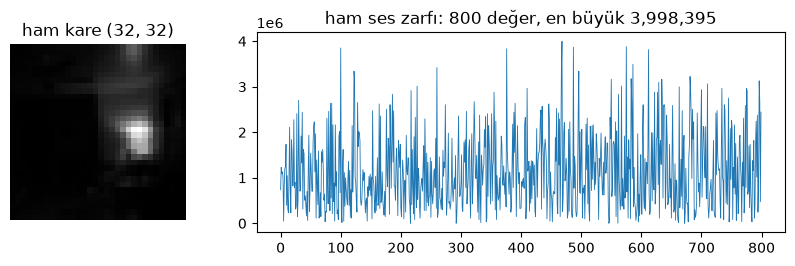

ham ortam satırı: {'tvoc_ppb': 0.0, 'temp_c': 25.3, 'rh_percent': 21.8, 'light_lux': 28.0, 'co2eq_ppm': 400.0}
ham etiket: {'occupied': 1, 'number': 2}


In [2]:
png = ROOT / "data/samples/H1/2019-11-26/1700/2019-11-26_170005_RS2_H1.png"   # pencerenin 5. saniyesindeki kare
aud_csv = ROOT / "data/samples/H1/H1_RS2_AUDIO/2019-11-26/1700/2019-11-26_170000_RS2_H1.csv"
env_csv = ROOT / "data/interim/H1/H1_RS2_ENV/2019-11-26_RS2_H1_env.csv"
gt_csv = ROOT / "data/interim/H1/2019-11-26_H1_groundtruth.csv"

raw_img = np.asarray(Image.open(png).convert("L"))
raw_aud = np.loadtxt(aud_csv)
raw_env = pd.read_csv(env_csv, index_col=0, parse_dates=True).loc["2019-11-26 17:00:00", ENV_COLS]
raw_gt = pd.read_csv(gt_csv, parse_dates=["timestamp"]).set_index("timestamp").loc["2019-11-26 17:00:00"]

fig, ax = plt.subplots(1, 2, figsize=(10, 2.6), gridspec_kw={"width_ratios": [1, 3]})
ax[0].imshow(raw_img, cmap="gray"); ax[0].set_title(f"ham kare {raw_img.shape}"); ax[0].axis("off")
ax[1].plot(raw_aud, lw=0.6); ax[1].set_title(f"ham ses zarfı: {len(raw_aud)} değer, en büyük {raw_aud.max():,.0f}")
plt.show()
print("ham ortam satırı:", raw_env.round(1).to_dict())
print("ham etiket:", raw_gt.to_dict())

## 2. Eşleştirme doğru mu? Ham dosya ↔ işlenmiş dizi (Kriter 4)

`src/build.py` her modaliteyi aynı 10 sn ızgaraya yazdı: satır *t* = [t, t+10). Aşağıda aynı pencerenin işlenmiş
dizideki satırını bulup ham dosyayla **birebir** karşılaştırıyoruz. Bütün `assert`'ler geçerse eşleştirme doğrudur.

In [3]:
lab = pd.read_parquet(OUT / "H1" / "labels.parquet")
i = int(np.flatnonzero(lab["ts"] == "2019-11-26 17:00:00")[0])
img = np.load(OUT / "H1" / "RS2_img.npy", mmap_mode="r")[i]
aud = np.load(OUT / "H1" / "RS2_aud.npy", mmap_mode="r")[i].astype("float64")
env = np.load(OUT / "H1" / "RS2_env.npy")[i]
meta = pd.read_parquet(OUT / "H1" / "RS2_img.parquet").iloc[i]

assert (img == raw_img).all()                                   # kare piksel piksel aynı
assert np.allclose(aud, np.log1p(raw_aud), rtol=1e-3)            # ses = log1p(ham) (float16 hassasiyeti)
assert np.allclose(env, raw_env.to_numpy(), equal_nan=True)      # ortam satırı aynı
assert lab.loc[i, "number"] == raw_gt["number"]                  # etiket aynı
print(f"satır {i}: kare (+{meta.offset} sn), ses, ortam ve etiket ham dosyalarla birebir aynı ✓")
print(f"etiket: {lab.loc[i, 'number']} kişi → sınıf {lab.loc[i, 'cls']} (0 / 1 / 2+)")

satır 6120: kare (+5 sn), ses, ortam ve etiket ham dosyalarla birebir aynı ✓
etiket: 2 kişi → sınıf 2 (0 / 1 / 2+)


Aynı pencerenin dört kanalı yan yana (rapor Şekil 1):

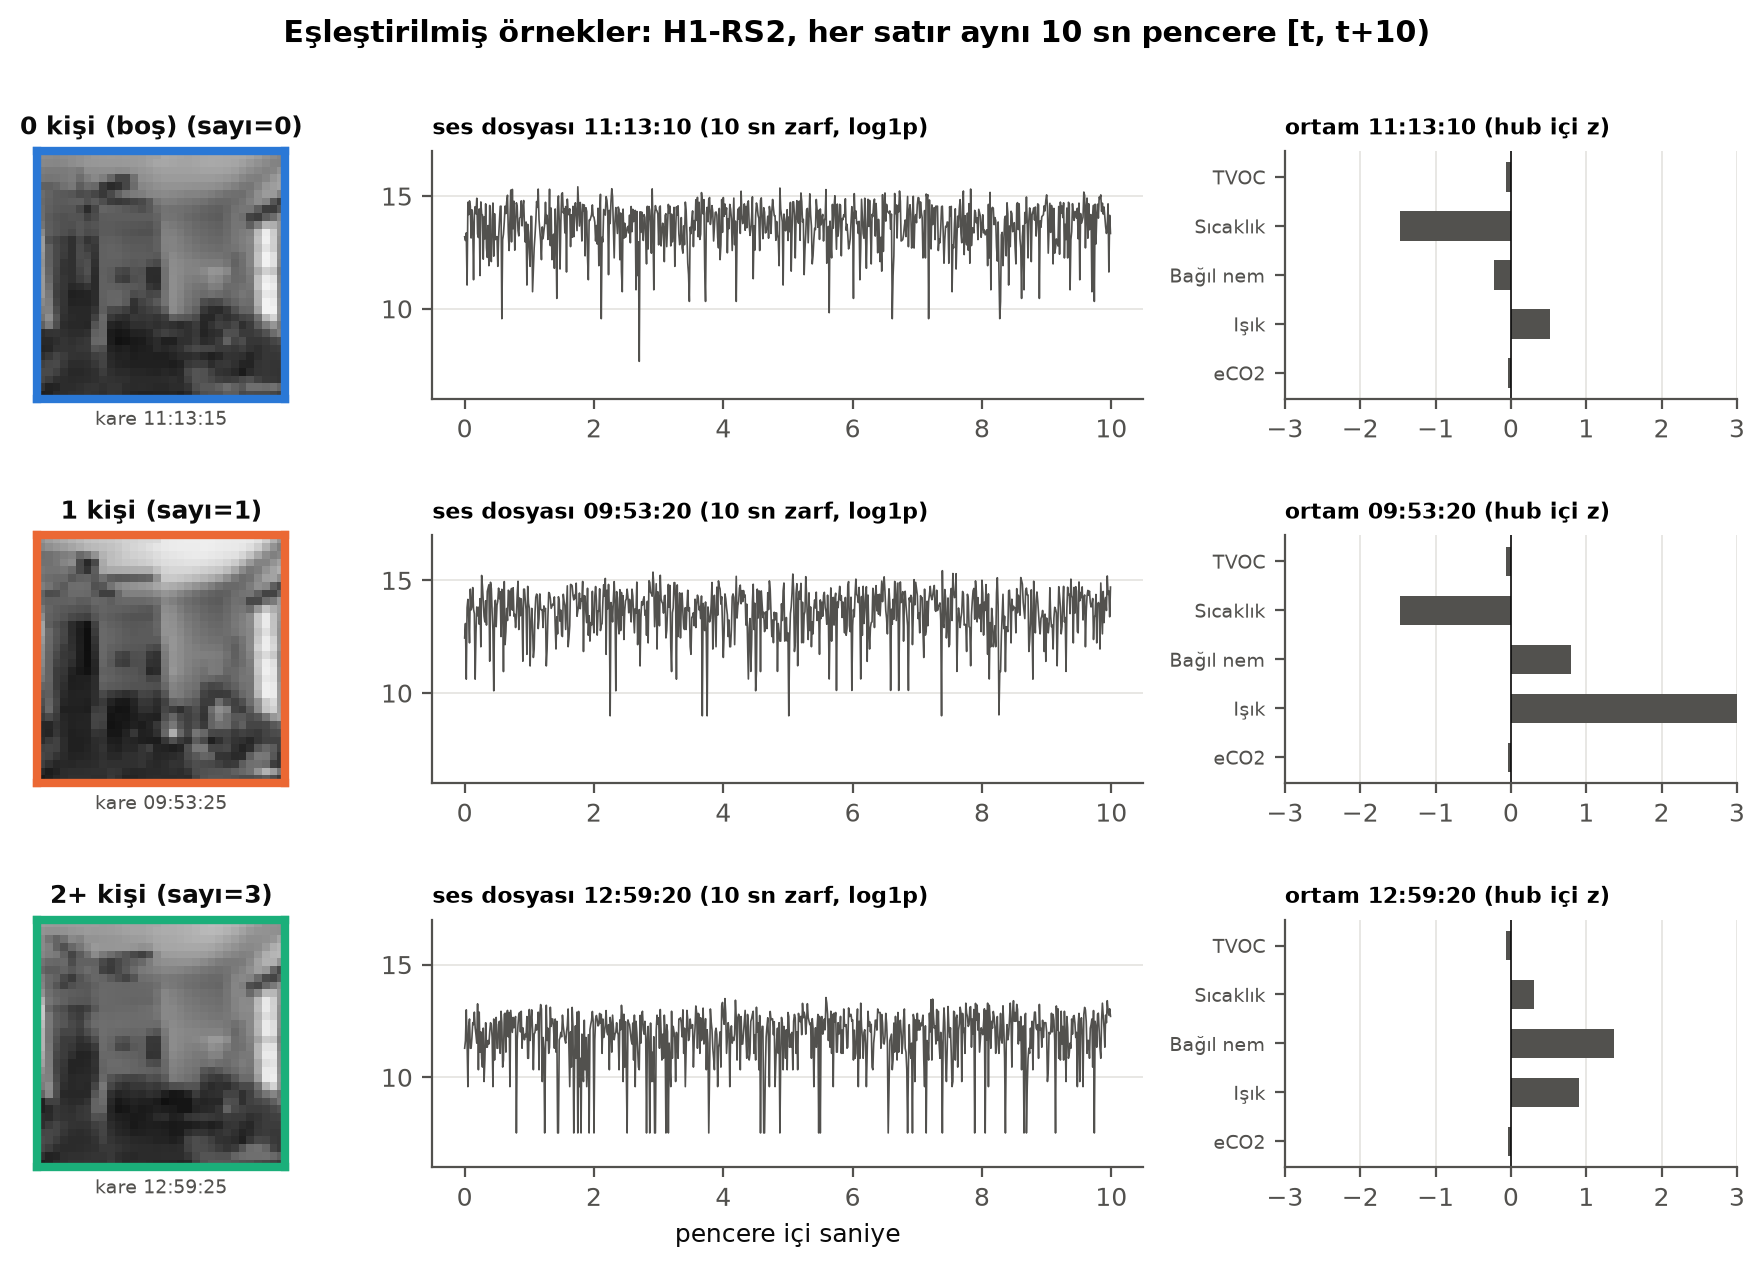

In [4]:
show("fig16_ornek_kartlari.png")

## 3. Veri miktarı ve özet (Kriter 2–3)

Tablolar `stats.json` dosyalarından kodla üretildi (`python src/eda.py tab01`); elle sayı yok.

In [5]:
md_file("reports/veri_ozeti.md")

# Veri özeti

`python src/eda.py tab01` ile `data/processed/*/stats.json`'dan üretilir; elle düzenleme.

## Ev bazında

| Ev | Gün | Pencere (10 sn) | Hub | 0 kişi | 1 kişi | 2+ kişi |
|---|---|---|---|---|---|---|
| H1 | 30 | 257,845 | 5 | 45,921 | 58,866 | 153,058 |
| H2 | 17 | 146,880 | 4 | 58,150 | 88,189 | 541 |
| H3 | 35 | 302,400 | 5 | 65,800 | 55,632 | 180,968 |
| H4 | 17 | 146,880 | 5 | 26,928 | 72,499 | 47,453 |
| H5 | 15 | 129,600 | 5 | 31,606 | 49,124 | 48,870 |
| H6 | 38 | 328,320 | 4 | 174,562 | 153,758 | 0 |
| **Toplam** | | **1,311,925** | | **402,967** | **478,068** | **430,890** |

## Ev × hub × modalite

Oranlar ızgaradaki pencere sayısına göre. *Ortam boş satır* = en az bir sensör değeri NaN. *Izgara dışı* = etiket aralığının dışında kalan (düşen) dosya. *Karanlık* = yazarların zip'ten çıkardığı kare (H2 için liste yayınlanmamış → 0).

| Ev | Hub | Ortam eşleşen % | Ortam boş satır % | Kare dosyası | Izgara dışı | Karesi olan pencere % | Karanlık kare | Ses dosyası | Ses eşleşen % | Ses ızgara dışı | Bozuk ses |
|---|---|---|---|---|---|---|---|---|---|---|---|
| H1 | RS1 | 97.5 | 10.0 | 1,420,185 | 7,962 | 54.8 | 1,167,778 | 244,033 | 94.2 | 1,239 | 0 |
| H1 | RS2 | 98.9 | 7.3 | 2,551,016 | 13,480 | 99.4 | 28,233 | 250,649 | 96.7 | 1,301 | 0 |
| H1 | RS3 | 97.6 | 9.2 | 1,438,878 | 6,781 | 55.6 | 1,140,795 | 244,892 | 94.5 | 1,239 | 0 |
| H1 | RS4 | 97.9 | 8.3 | 1,326,044 | 0 | 51.5 | 1,261,672 | 247,617 | 95.5 | 1,263 | 0 |
| H1 | RS5 | 98.0 | 8.1 | 1,177,783 | 0 | 45.8 | 1,336,033 | 248,015 | 95.7 | 1,185 | 0 |
| H2 | RS1 | 97.4 | 7.3 | 1,305,548 | 284,305 | 69.6 | 0 | 132,708 | 90.3 | 6 | 0 |
| H2 | RS2 | 95.7 | 9.2 | 1,845,042 | 741,120 | 76.4 | 0 | 131,192 | 89.3 | 6 | 0 |
| H2 | RS4 | 96.3 | 8.3 | 1,840,174 | 371,912 | 100.0 | 0 | 134,480 | 91.6 | 6 | 0 |
| H2 | RS5 | 98.1 | 7.6 | 1,739,458 | 612,364 | 76.8 | 0 | 134,904 | 91.8 | 6 | 0 |
| H3 | RS1 | 95.3 | 9.8 | 1,882,313 | 0 | 62.4 | 1,134,263 | 287,097 | 94.9 | 11 | 0 |
| H3 | RS2 | 94.5 | 10.7 | 2,017,105 | 0 | 66.8 | 1,002,722 | 286,110 | 94.6 | 6 | 0 |
| H3 | RS3 | 97.2 | 7.5 | 2,034,641 | 0 | 67.4 | 989,931 | 291,803 | 96.5 | 12 | 0 |
| H3 | RS4 | 97.5 | 7.1 | 1,768,029 | 0 | 58.6 | 1,252,551 | 292,751 | 96.8 | 12 | 0 |
| H3 | RS5 | 95.5 | 9.4 | 1,879,615 | 0 | 62.3 | 1,140,273 | 294,592 | 97.4 | 12 | 0 |
| H4 | RS1 | 98.7 | 6.5 | 962,159 | 0 | 65.5 | 507,835 | 122,983 | 83.7 | 12 | 0 |
| H4 | RS2 | 98.6 | 6.1 | 907,819 | 0 | 64.0 | 515,558 | 139,039 | 94.7 | 12 | 0 |
| H4 | RS3 | 98.8 | 6.4 | 936,805 | 0 | 63.8 | 533,435 | 141,761 | 96.5 | 12 | 0 |
| H4 | RS4 | 94.9 | 9.4 | 816,571 | 0 | 57.6 | 498,429 | 126,692 | 86.2 | 11 | 0 |
| H4 | RS5 | 98.6 | 6.6 | 942,064 | 0 | 64.2 | 528,165 | 142,594 | 97.1 | 12 | 0 |
| H5 | RS1 | 21.9 | 79.4 | 875,592 | 0 | 67.6 | 417,690 | 28,607 | 22.1 | 0 | 0 |
| H5 | RS2 | 96.5 | 8.1 | 884,095 | 0 | 68.3 | 412,266 | 125,255 | 96.6 | 6 | 0 |
| H5 | RS3 | 96.6 | 7.9 | 881,424 | 0 | 68.7 | 403,127 | 124,704 | 96.2 | 6 | 0 |
| H5 | RS4 | 94.0 | 10.9 | 805,385 | 0 | 65.1 | 432,338 | 111,972 | 86.4 | 6 | 0 |
| H5 | RS5 | 96.1 | 9.2 | 869,726 | 0 | 67.1 | 427,193 | 115,350 | 89.0 | 6 | 0 |
| H6 | BS2 | 96.0 | 9.9 | 1,758,593 | 0 | 53.7 | 1,484,628 | 0 | 0.0 | 0 | 0 |
| H6 | BS3 | 97.9 | 8.5 | 1,961,635 | 0 | 59.9 | 1,239,581 | 303,118 | 92.3 | 12 | 0 |
| H6 | BS4 | 96.5 | 9.4 | 1,982,761 | 0 | 60.5 | 1,234,168 | 304,525 | 92.7 | 12 | 0 |
| H6 | BS5 | 95.8 | 10.4 | 2,037,931 | 0 | 62.2 | 1,212,808 | 305,583 | 93.1 | 12 | 0 |

**Toplam:** 40,848,391 kare dosyası (2,037,924 ızgara dışı), 20,301,472 karanlık kare (listede, görüntüsü yok), 5,313,026 ses dosyası (5,306,603 eşleşti, 6,423 ızgara dışı). 10'dan fazla karesi olan (tekrar kare içeren) pencere: 0.

## Yazarların metadata'sı ile karşılaştırma

| Ev | Hub | Ses: yazar | Ses: biz | Ortam (tam satır): yazar | Ortam: biz |
|---|---|---|---|---|---|
| H1 | RS1 | 0.94 | 0.94 | 0.90 | 0.90 |
| H2 | RS1 | 0.90 | 0.90 | 0.93 | 0.93 |
| H3 | RS1 | 0.95 | 0.95 | 0.90 | 0.90 |
| H4 | RS1 | 0.84 | 0.84 | 0.93 | 0.93 |
| H5 | RS1 | 0.22 | 0.22 | 0.21 | 0.21 |
| H6 | BS2 | 0.00 | 0.00 | 0.90 | 0.90 |

En büyük fark: 0.0.


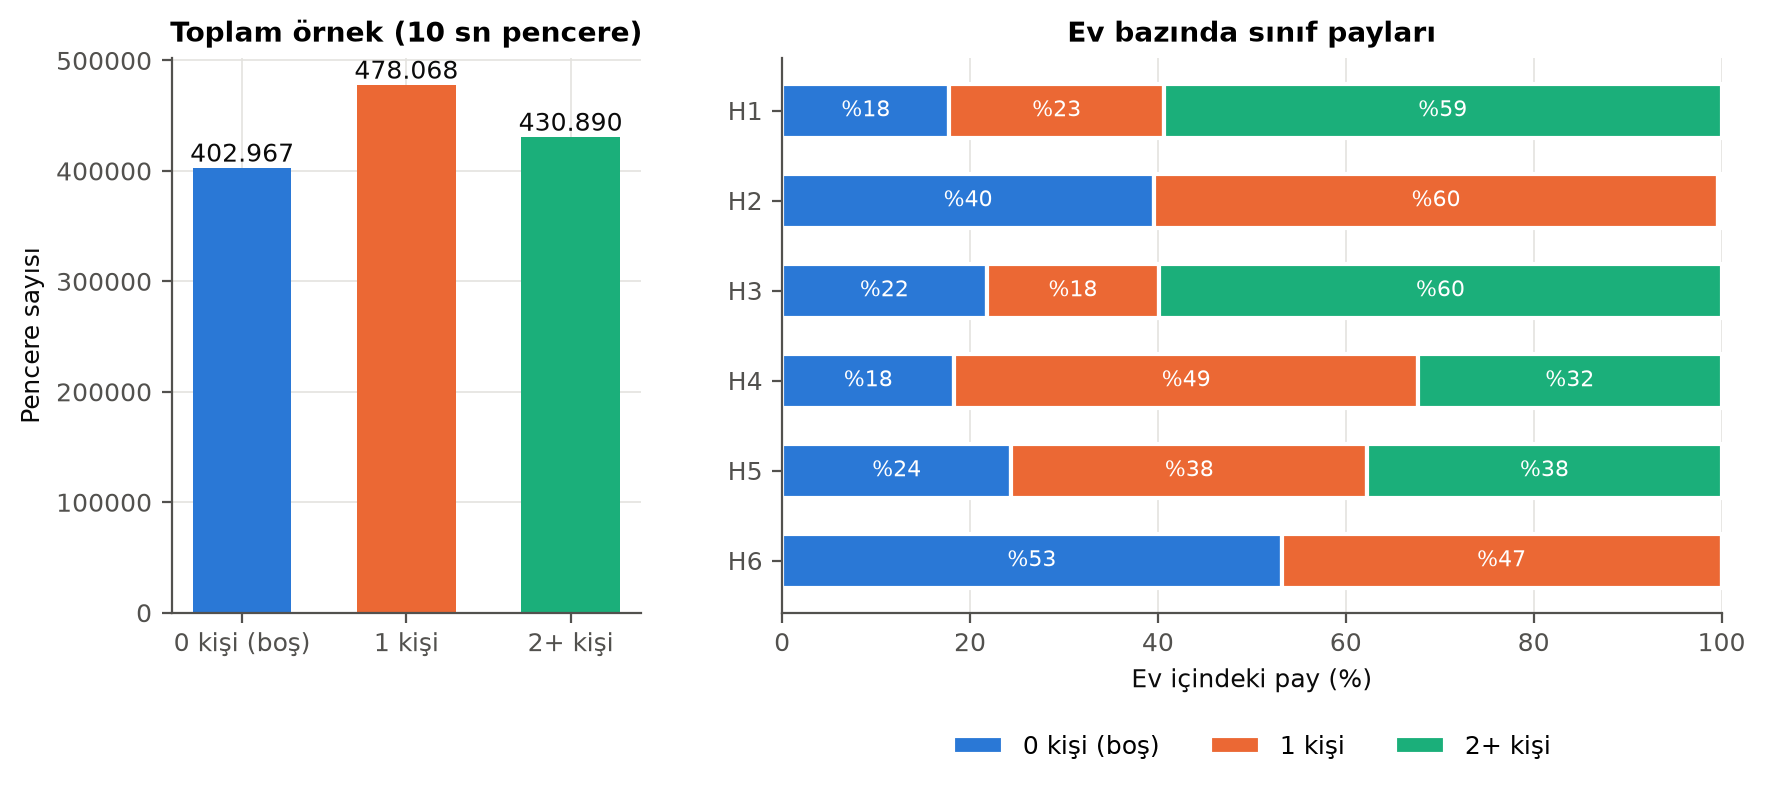

In [6]:
show("fig01_sinif_dagilimi.png")

**Yorum:** toplamda üç sınıf dengeli (yönerge: ≥3 sınıf, ≥150/sınıf ✓), ama tek kişilik H2 ve H6'da 2+ yok →
ev bazlı testte sınıf eksikliği.

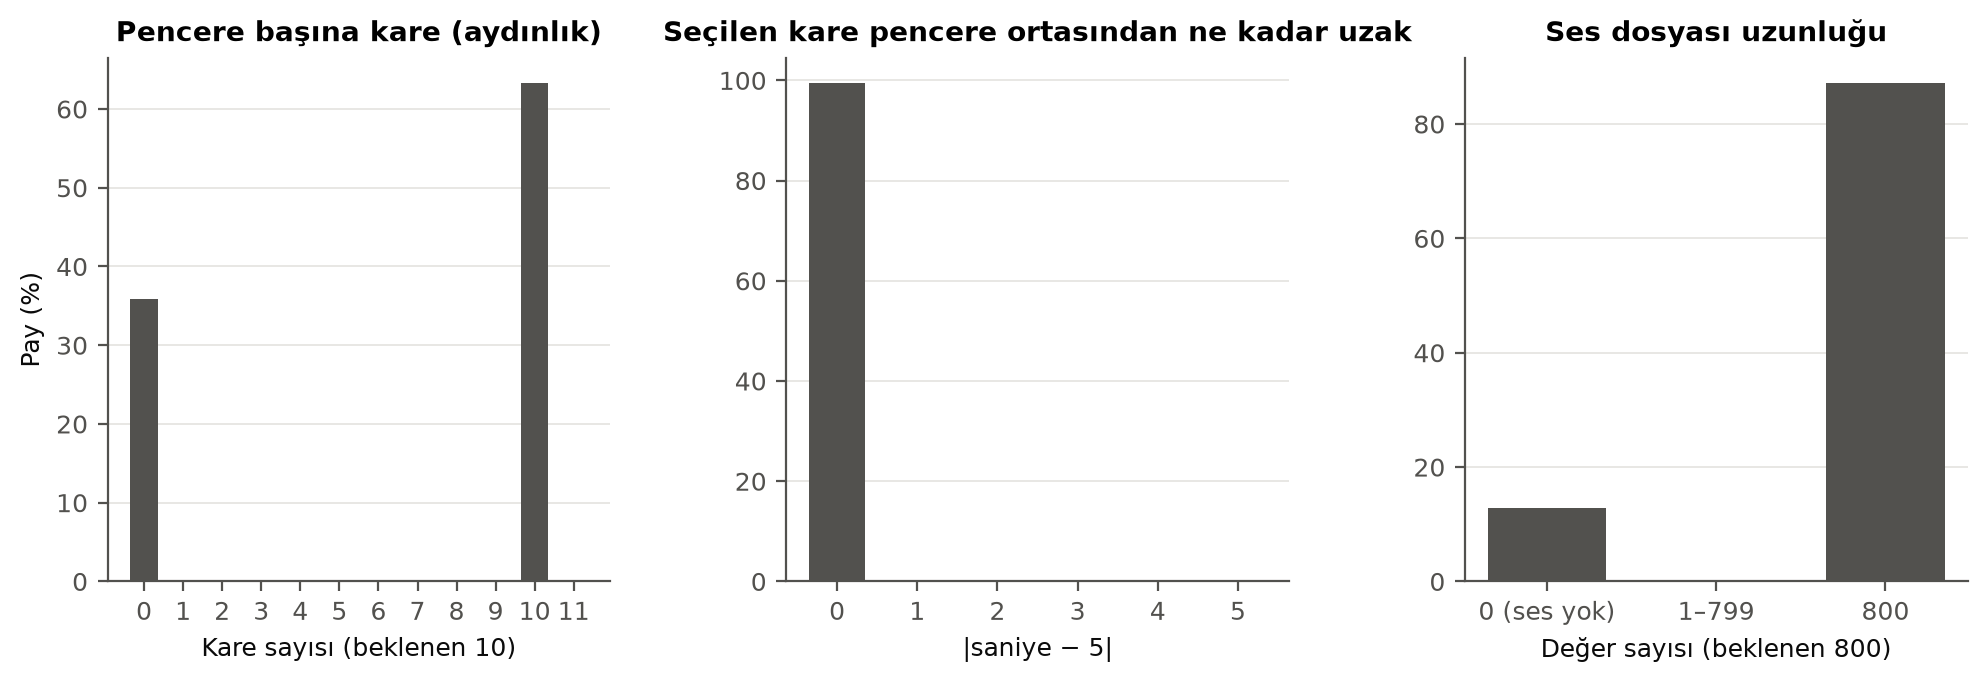

In [7]:
show("fig15_modalite_yapisi.png")

## 4. Eksik modalite ve etiket kalitesi (Kriter 4)

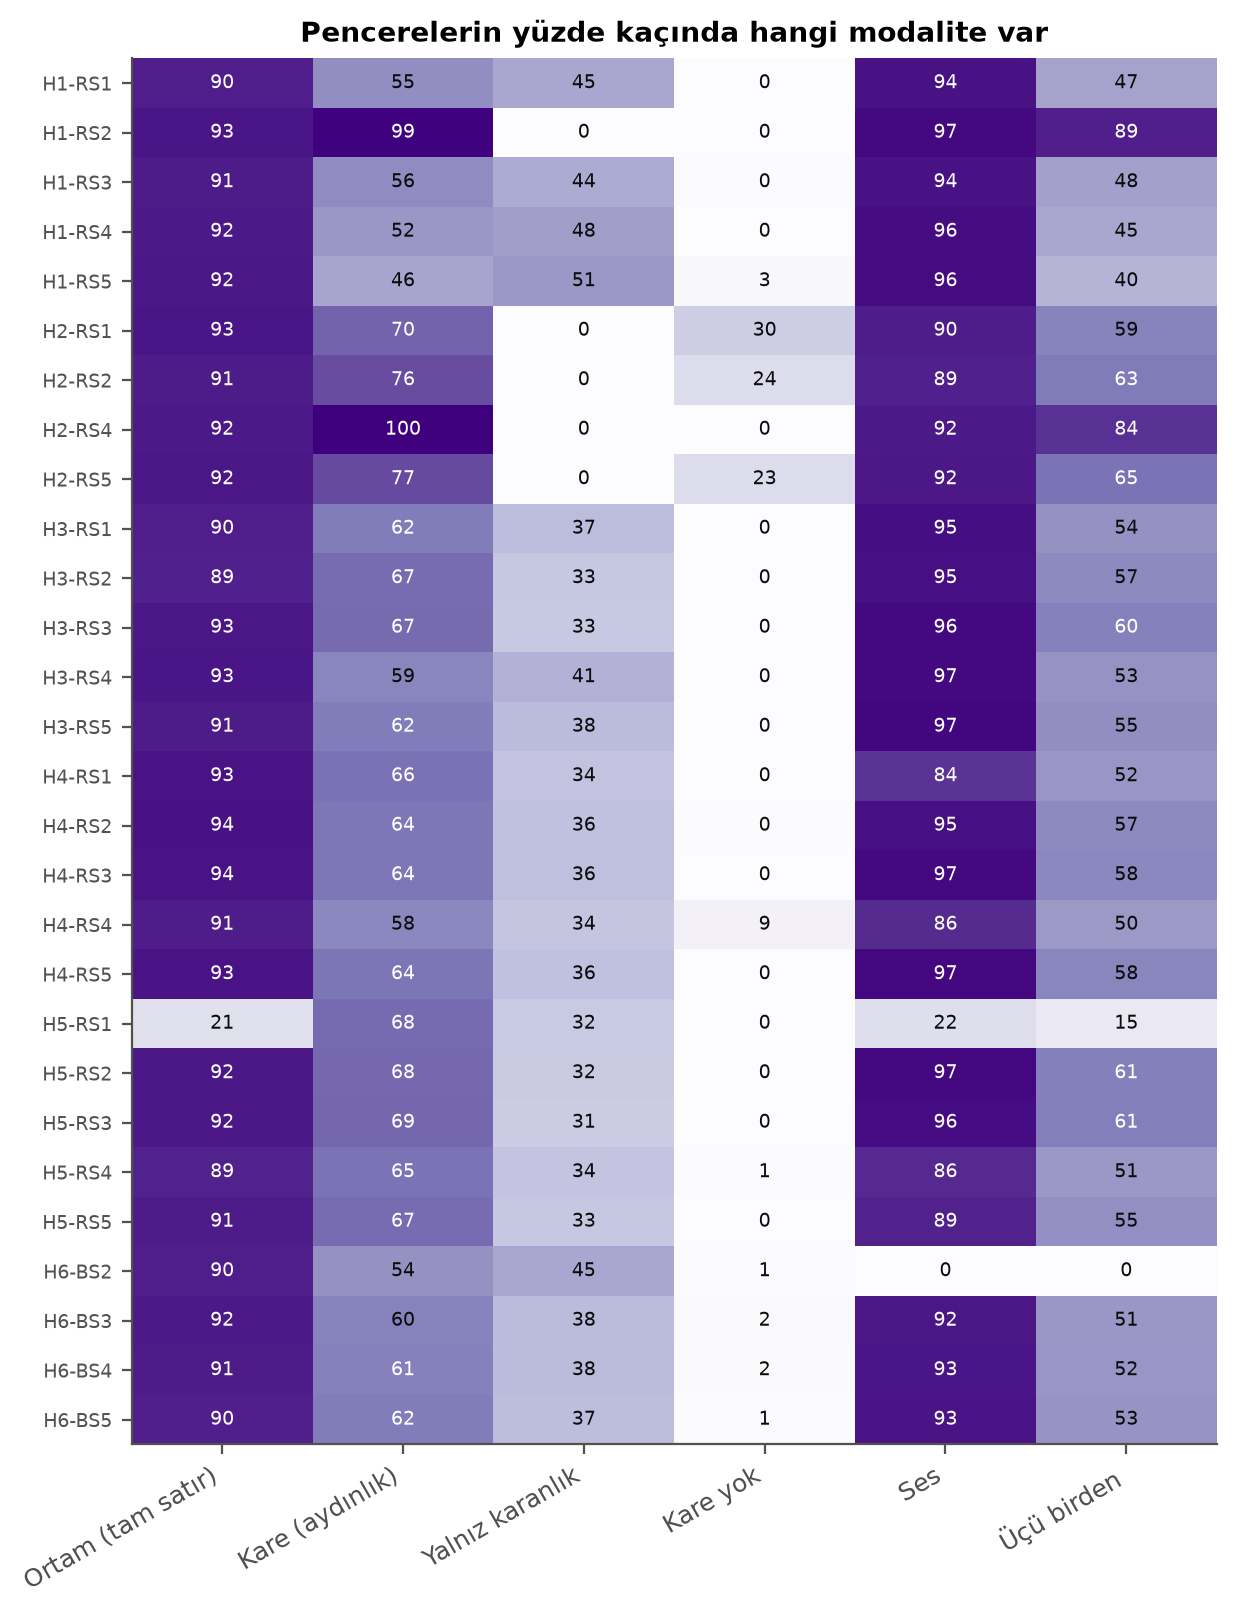

In [8]:
show("fig07_eksik_modalite.png", 600)

**Yorum:** üç modalitenin birlikte olduğu pencere ortalama %53. Görüntü eksikliği gece karanlığından →
rastgele değil; projenin "eksik modaliteye dayanıklı" iddiasının gerekçesi.

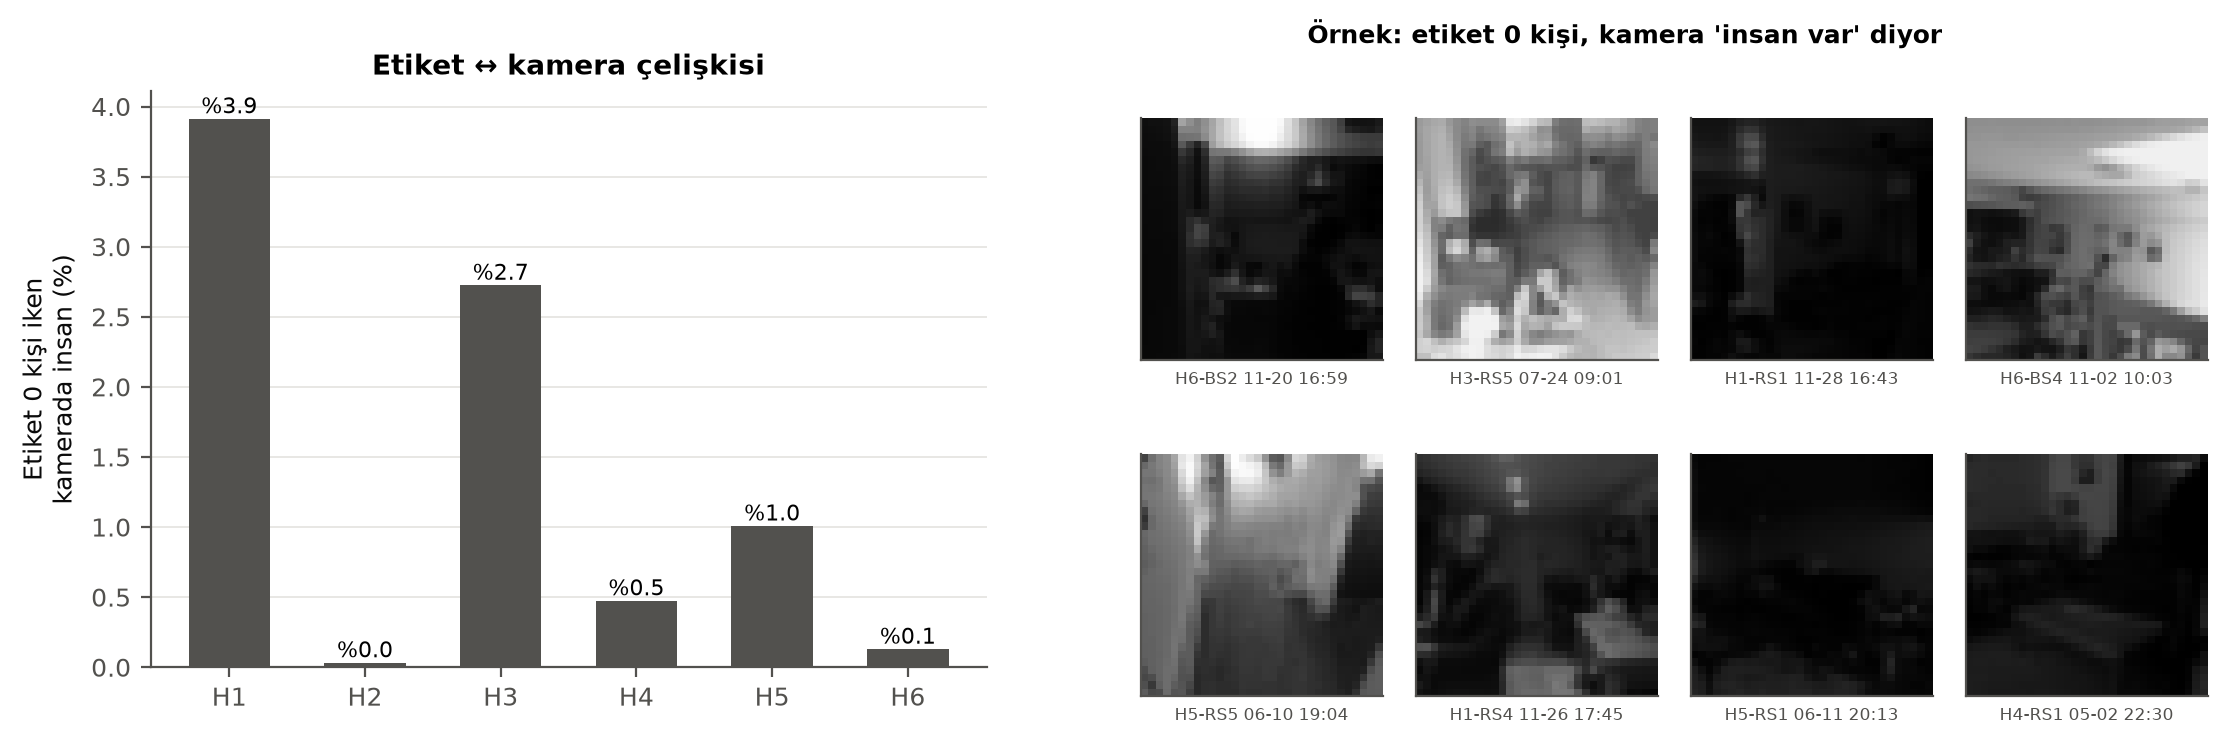

In [9]:
show("fig14_etiket_kamera.png")

**Yorum:** kişi sayısı etiketi yazarlarca doğrulanmamış. Bağımsız kaynak (kamerada YOLO ile insan tespiti) ile
çelişki en kötü evde %3,9 → etiket gürültüsü düşük ama sıfır değil.

### Neden 0 / 1 / 2+?
Kişi sayısı giriş-çıkış kayıtlarından gelir (misafirler dahil). Aşağıdaki tablo `src/eda.py tab05` ile üretilir: sakin sayısını aşan (misafir) pencereler ve kamerada insan görülme oranının kişi sayısına göre değişimi.

In [10]:
md_file("reports/sinif_gerekcesi.md")

# Sınıf gerekçesi: neden 0 / 1 / 2+?

`python src/eda.py tab05` ile üretilir.

## Etiketteki kişi sayısı ve ev sakinleri

| Ev | Sakin | Etikette en fazla | Sakin sayısını aşan pencere | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|---|---|---|
| H1 | 4 | 4 | 0 (0.0%) | 45,921 | 58,866 | 76,696 | 51,980 | 24,382 | 0 |
| H2 | 1 | 2 | 541 (0.4%) | 58,150 | 88,189 | 541 | 0 | 0 | 0 |
| H3 | 4 | 5 | 42,526 (14.1%) | 65,800 | 55,632 | 42,945 | 72,369 | 23,128 | 42,526 |
| H4 | 3 | 3 | 0 (0.0%) | 26,928 | 72,499 | 36,715 | 10,738 | 0 | 0 |
| H5 | 2 | 2 | 0 (0.0%) | 31,606 | 49,124 | 48,870 | 0 | 0 | 0 |
| H6 | 1 | 1 | 0 (0.0%) | 174,562 | 153,758 | 0 | 0 | 0 | 0 |

## Kamerada insan görülen pencere oranı (en az bir kutuda, %)

| Kişi sayısı | Gündüz 06–24 | Gece 00–06 |
|---|---|---|
| 0 | 1.3 | 0.0 |
| 1 | 14.7 | 13.2 |
| 2 | 32.3 | 0.7 |
| 3 | 32.1 | 2.6 |
| 4+ | 33.7 | 1.3 |


**Yorum:** gündüz kamerada insan görülme oranı 1 kişiden 2 kişiye iki katına çıkıyor, ama 2, 3 ve 4+ kişide aynı (~%32–34). Kutular yalnız ortak alanları görüyor; sensör açısından 2'den sonrası ayırt edilemiyor → 2 ve üzeri tek sınıf. 5 kişi yalnız H3'te ve bir misafir döneminde var. Gece 2+ kişide kamera neredeyse hiç insan görmüyor (yatak odaları izlenmiyor) → saat kısayolu riski.

## 5. Temizleme: kurallar canlı (Kriter 5)

Kurallar `src/clean.py`'de; işlenmiş veri ham kalır, temizleme okunurken uygulanır.

In [11]:
x = np.array([[0, 25.0, 3285.0, 10, 400], [5, -12.7, 40, 20, 450]], "float32")   # iki uydurma satır
print("önce :", np.round(x, 1).tolist())
print("sonra:", np.round(clean_env(x, "RS1", ENV_COLS), 1).tolist(), "  ← imkânsız nem ve sıcaklık NaN")
g = np.array([[1], [np.nan], [np.nan], [4]], "float32")
print("boşluk doldurma:", g.ravel().tolist(), "→", fill_short_gaps(g).ravel().tolist())

önce : [[0.0, 25.0, 3285.0, 10.0, 400.0], [5.0, -12.699999809265137, 40.0, 20.0, 450.0]]
sonra: [[0.0, 25.0, nan, 10.0, 400.0], [5.0, nan, 40.0, 20.0, 450.0]]   ← imkânsız nem ve sıcaklık NaN
boşluk doldurma: [1.0, nan, nan, 4.0] → [1.0, 2.0, 3.0, 4.0]


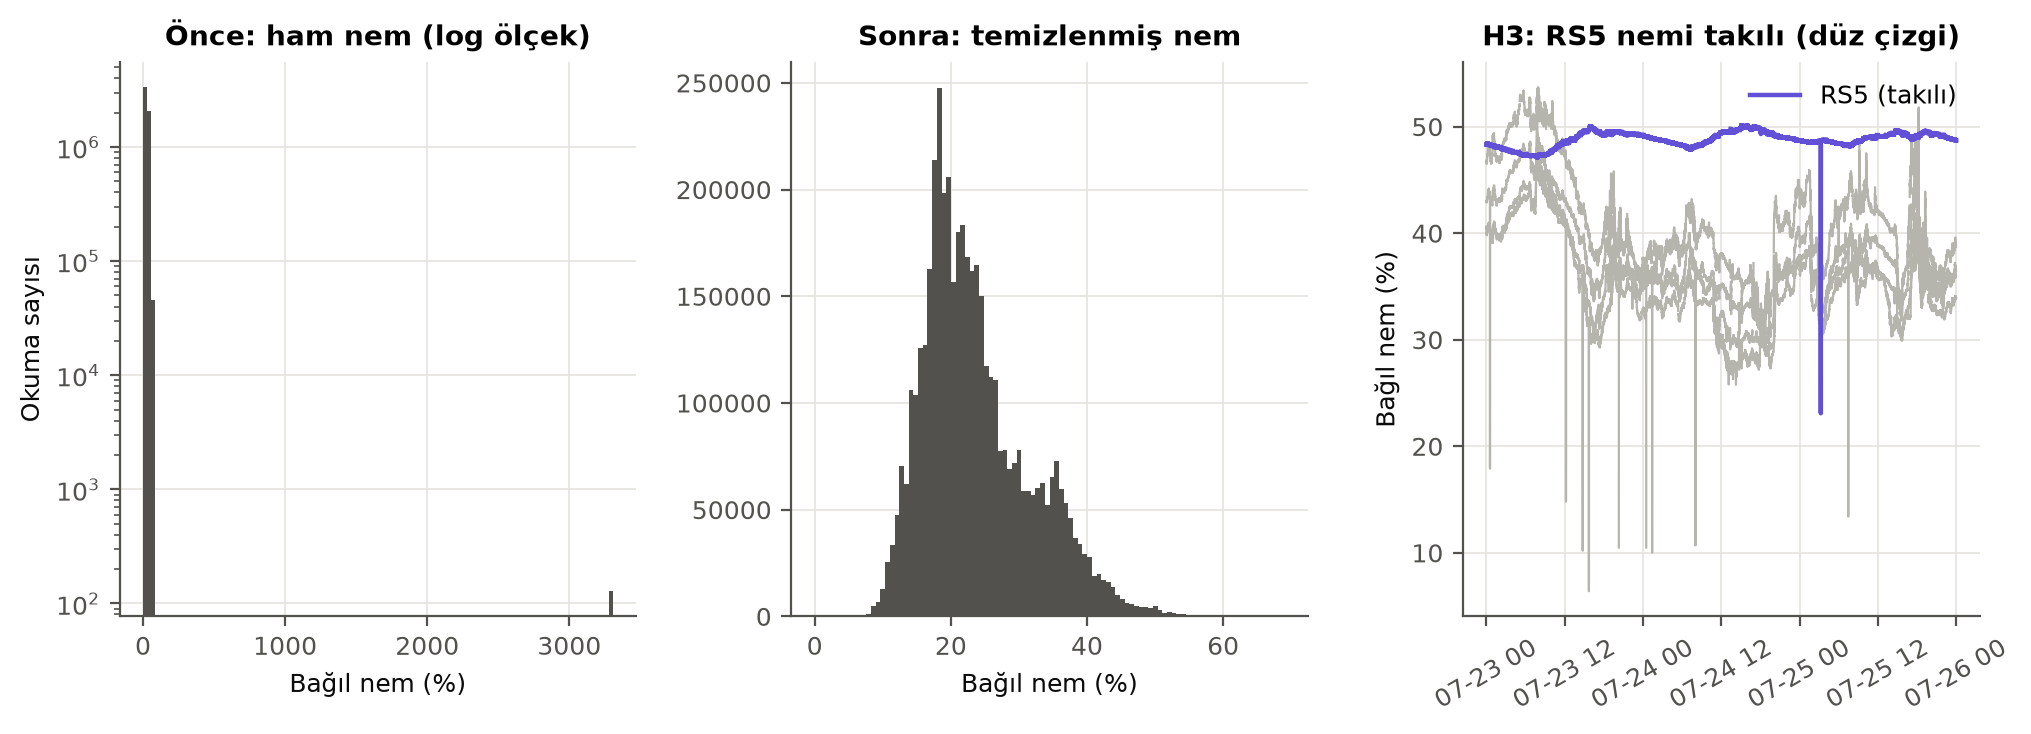

In [12]:
show("fig05_nem_temizleme.png")

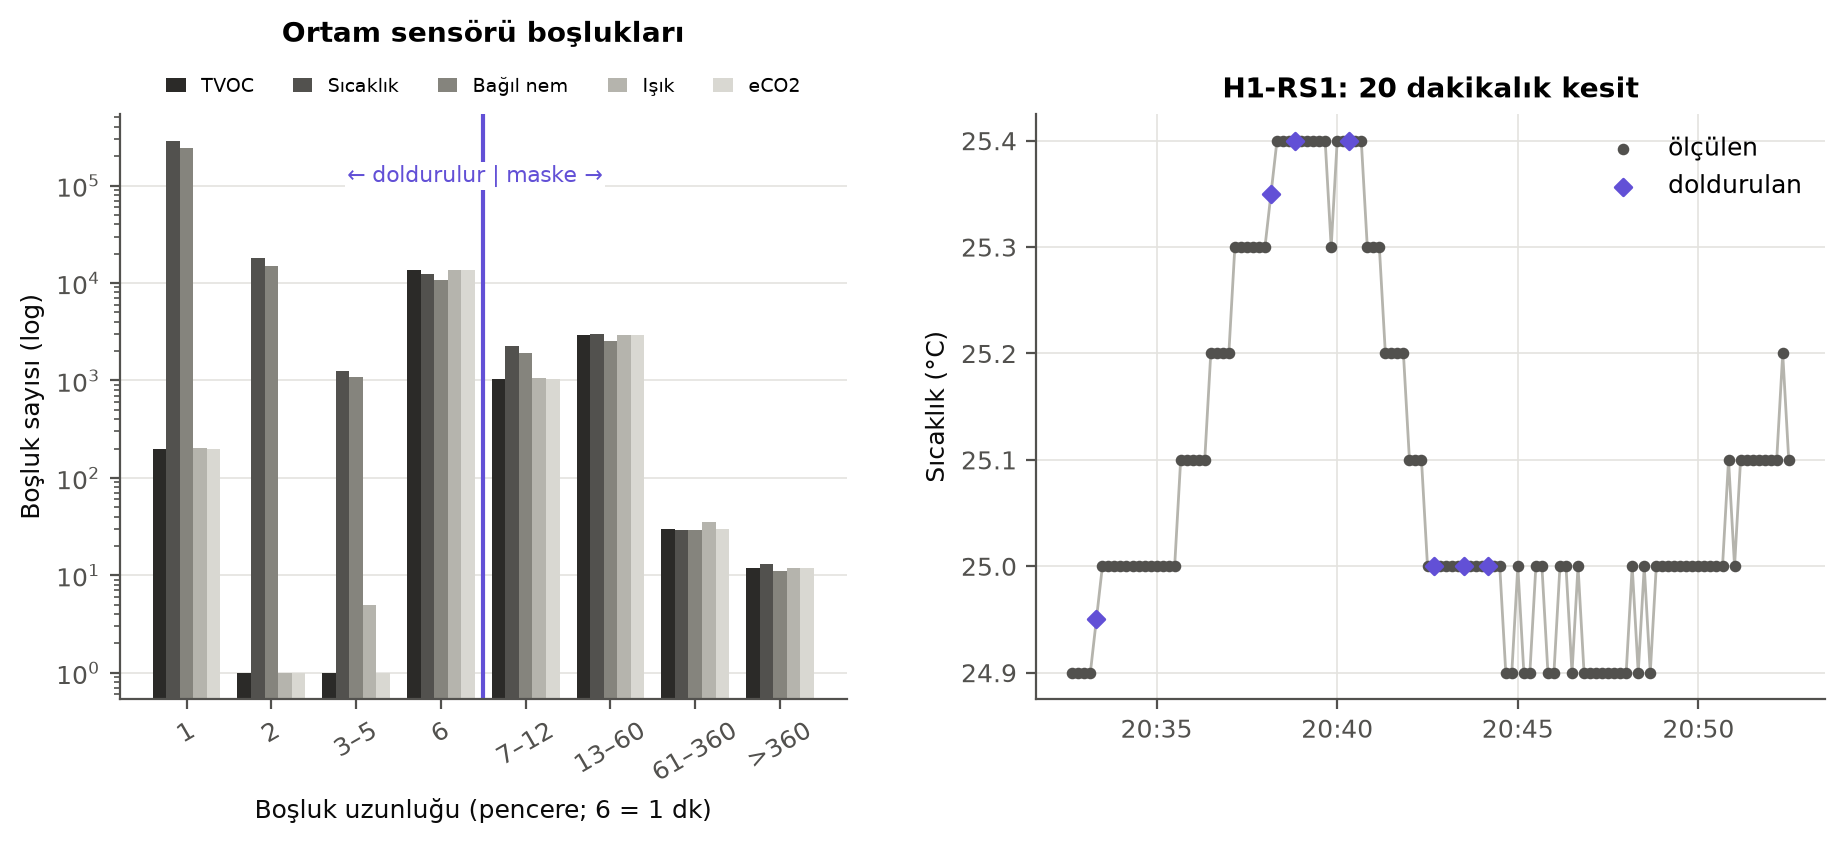

In [13]:
show("fig17_ortam_doldurma.png")

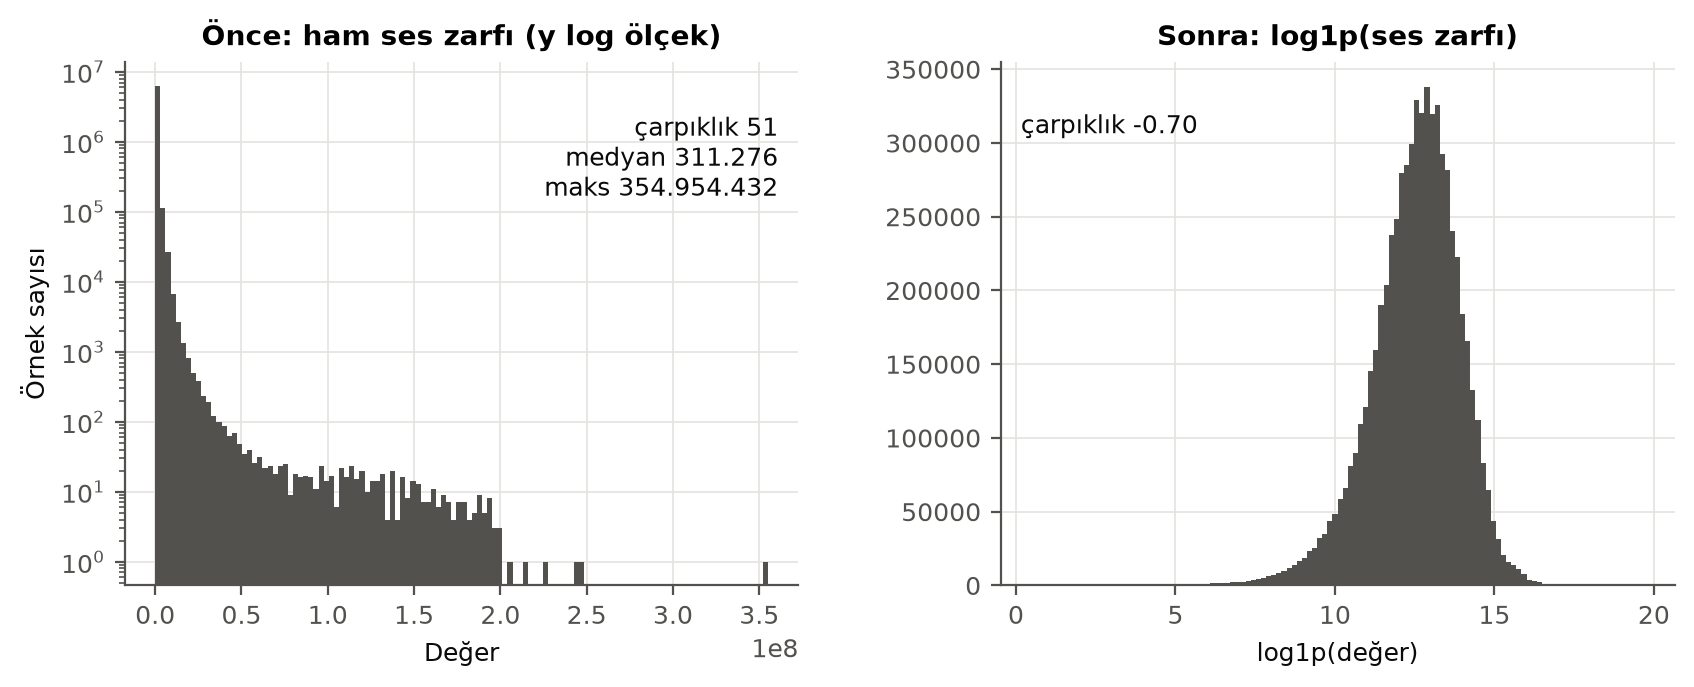

In [14]:
show("fig12_ses_log.png")

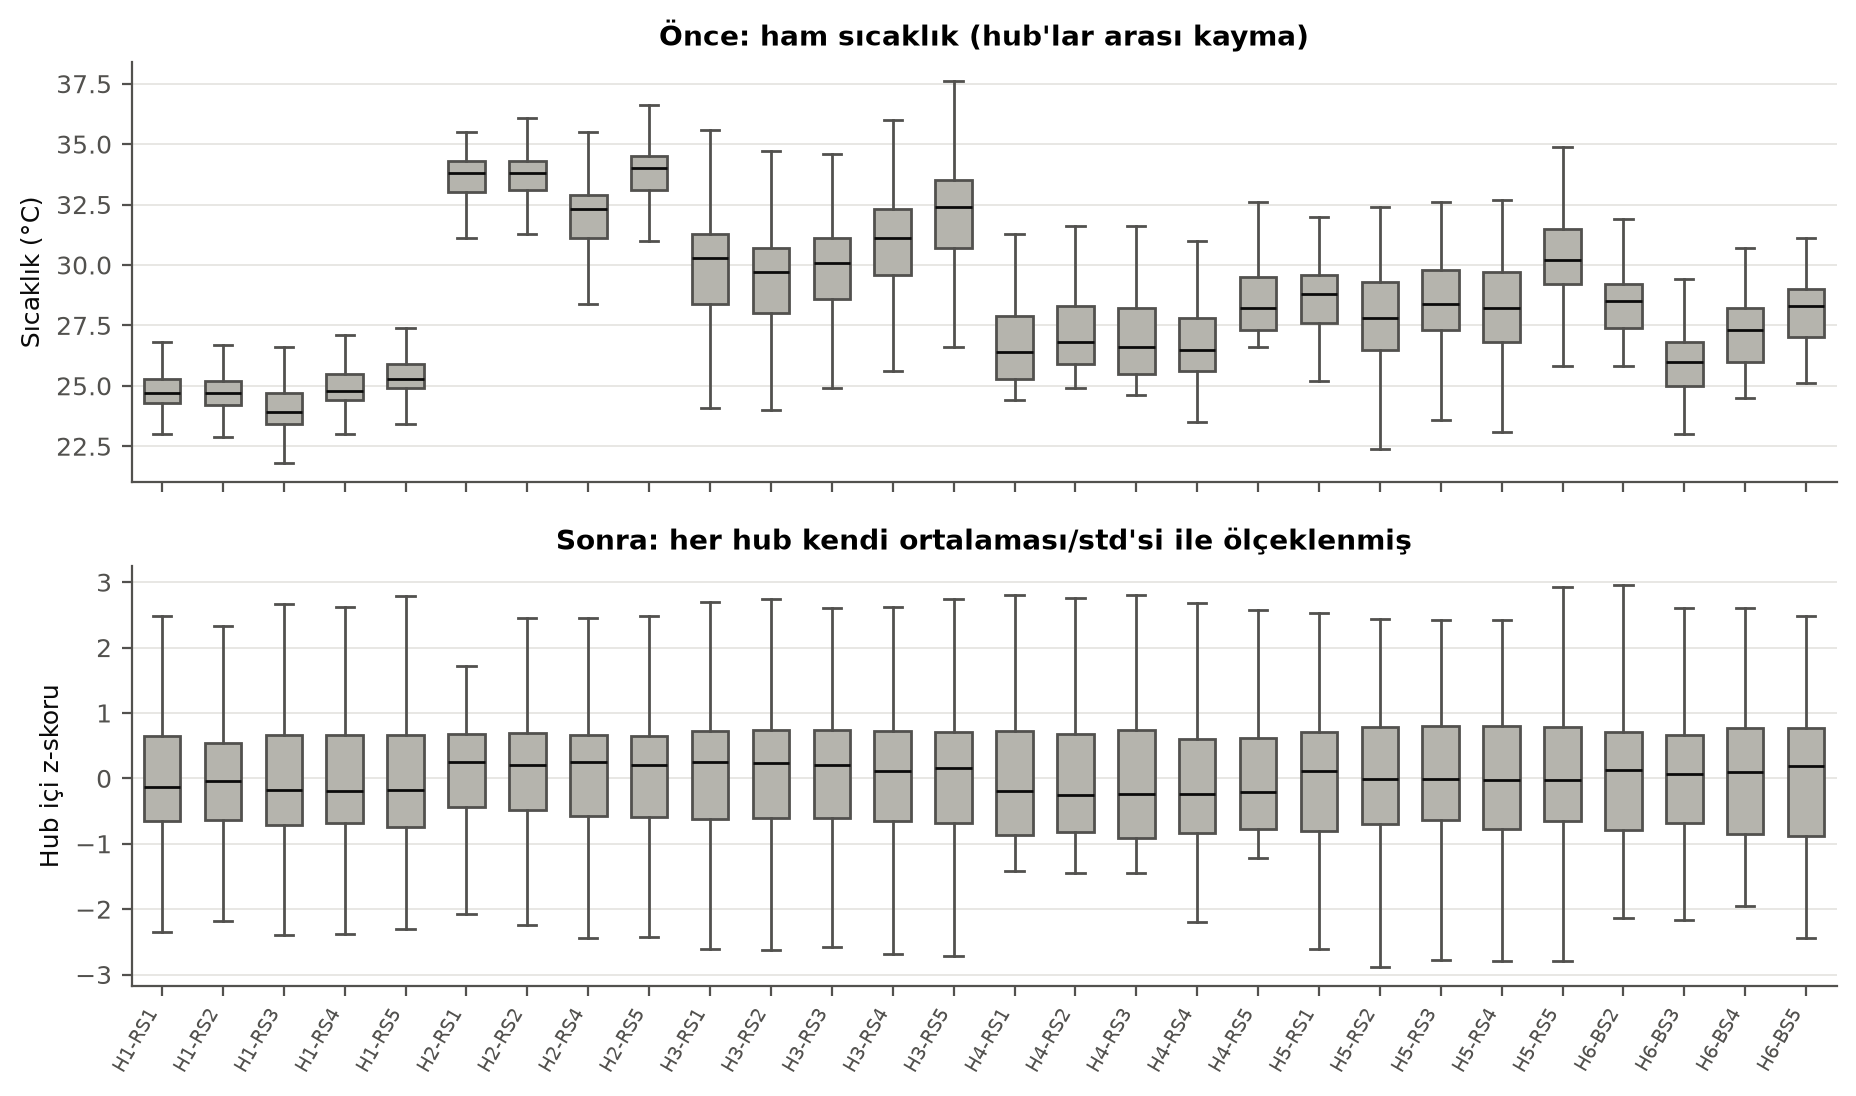

In [15]:
show("fig13_hub_normalizasyon.png")

In [16]:
md_file("reports/temizleme_dokumu.md")

# Temizleme dökümü (ortam sensörleri)

`python src/eda.py tab03`. Birim: hücre (pencere × sensör), toplam 30,422,125 hücre = 6,084,425 hub-pencere × 5 sensör. Görüntü ve ses dosyalarında bozuk/şekilsiz kayıt 0 (`reports/veri_ozeti.md`).

| Adım | Hücre | Toplamın %'si |
|---|---|---|
| Ham veride boş (NaN) hücre | 2,105,487 | 6.921 |
| Aralık dışı → NaN: TVOC (ppb) (0–60000) | 0 | 0.000 |
| Aralık dışı → NaN: Sıcaklık (°C) (0–45) | 3 | 0.000 |
| Aralık dışı → NaN: Bağıl nem (%) (0–100) | 128 | 0.000 |
| Aralık dışı → NaN: Işık (lux) (0–100000) | 1,049 | 0.003 |
| Aralık dışı → NaN: eCO2 (ppm) (400–60000) | 0 | 0.000 |
| Takılı RS5 nem sensörü → NaN (geçerli okuma) | 901,575 | 2.964 |
| Kısa boşluk (≤ 6 pencere) doğrusal doldurulan | 991,440 | 3.259 |
| Temizleme + doldurma sonrası kalan NaN (maske) | 2,016,802 | 6.629 |

Beş sensörü de dolu hub-pencere: önce 5,465,099 (%89.8), sonra 4,903,610 (%80.6). Düşüşün nedeni RS5 neminin tamamen çıkarılması; RS5 dışındaki hub'larda tam satır oranı %89.5 → %96.1 (doldurmanın kazancı).

**Bilgi kaybı:** aralık dışı kural yalnız fiziksel olarak imkânsız okumaları siler (toplamın binde birinden az). RS5 nemi bütünüyle kaybedilir, ama aynı evde 3–4 başka hub'ın nemi kaldığı için ev düzeyinde nem bilgisi korunur. Hiçbir pencere (örnek) silinmez; eksik değer maskelenir.


## 6. Keşifsel analiz (Kriter 6)

### 6.1 Sınıf farkları ve özet istatistikler

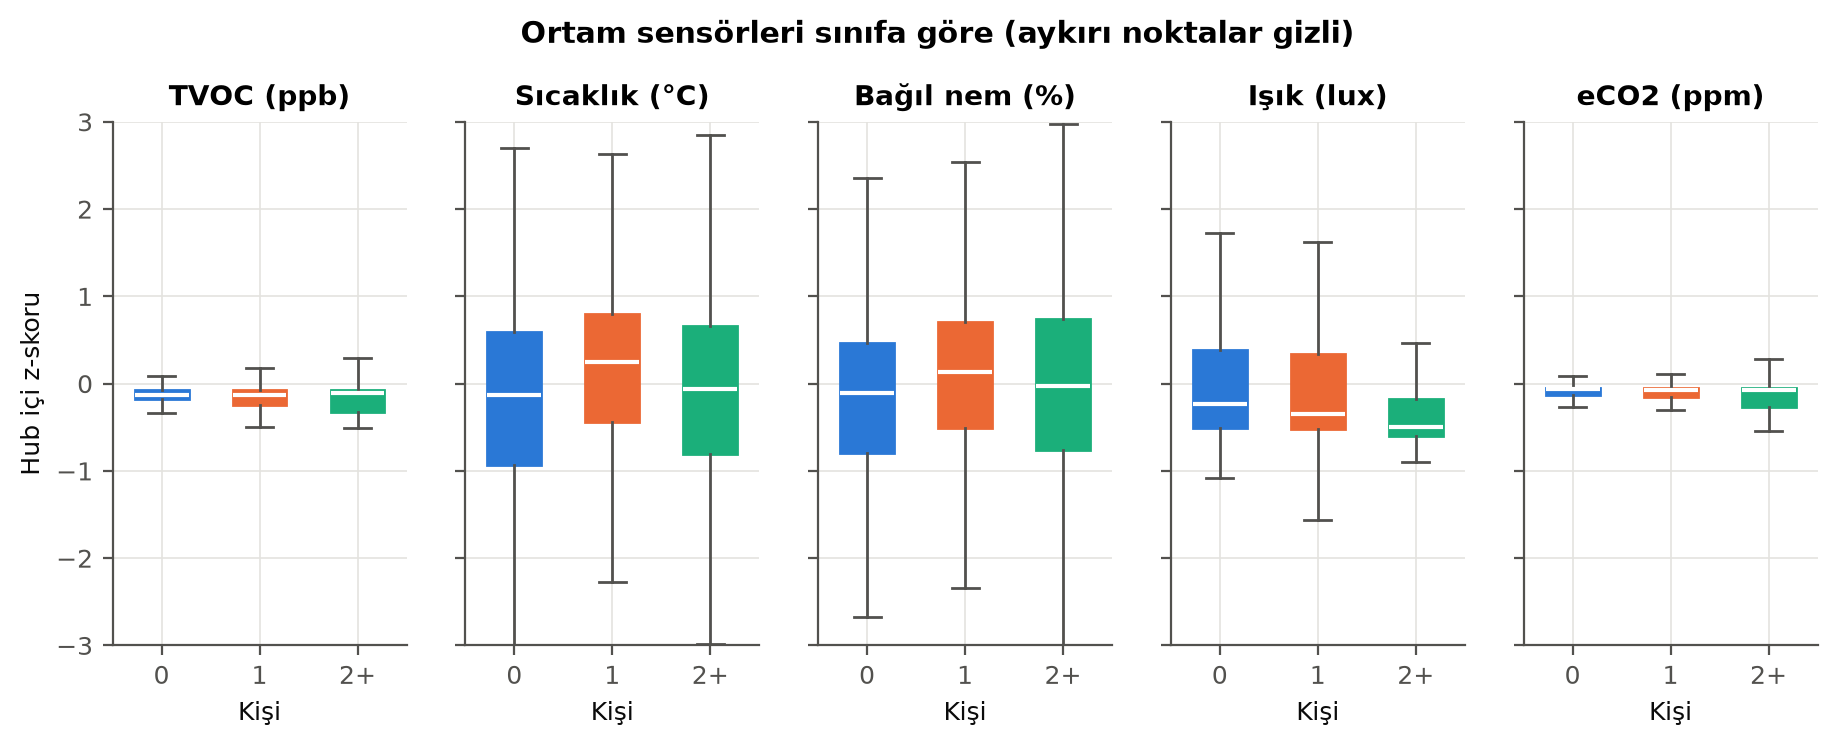

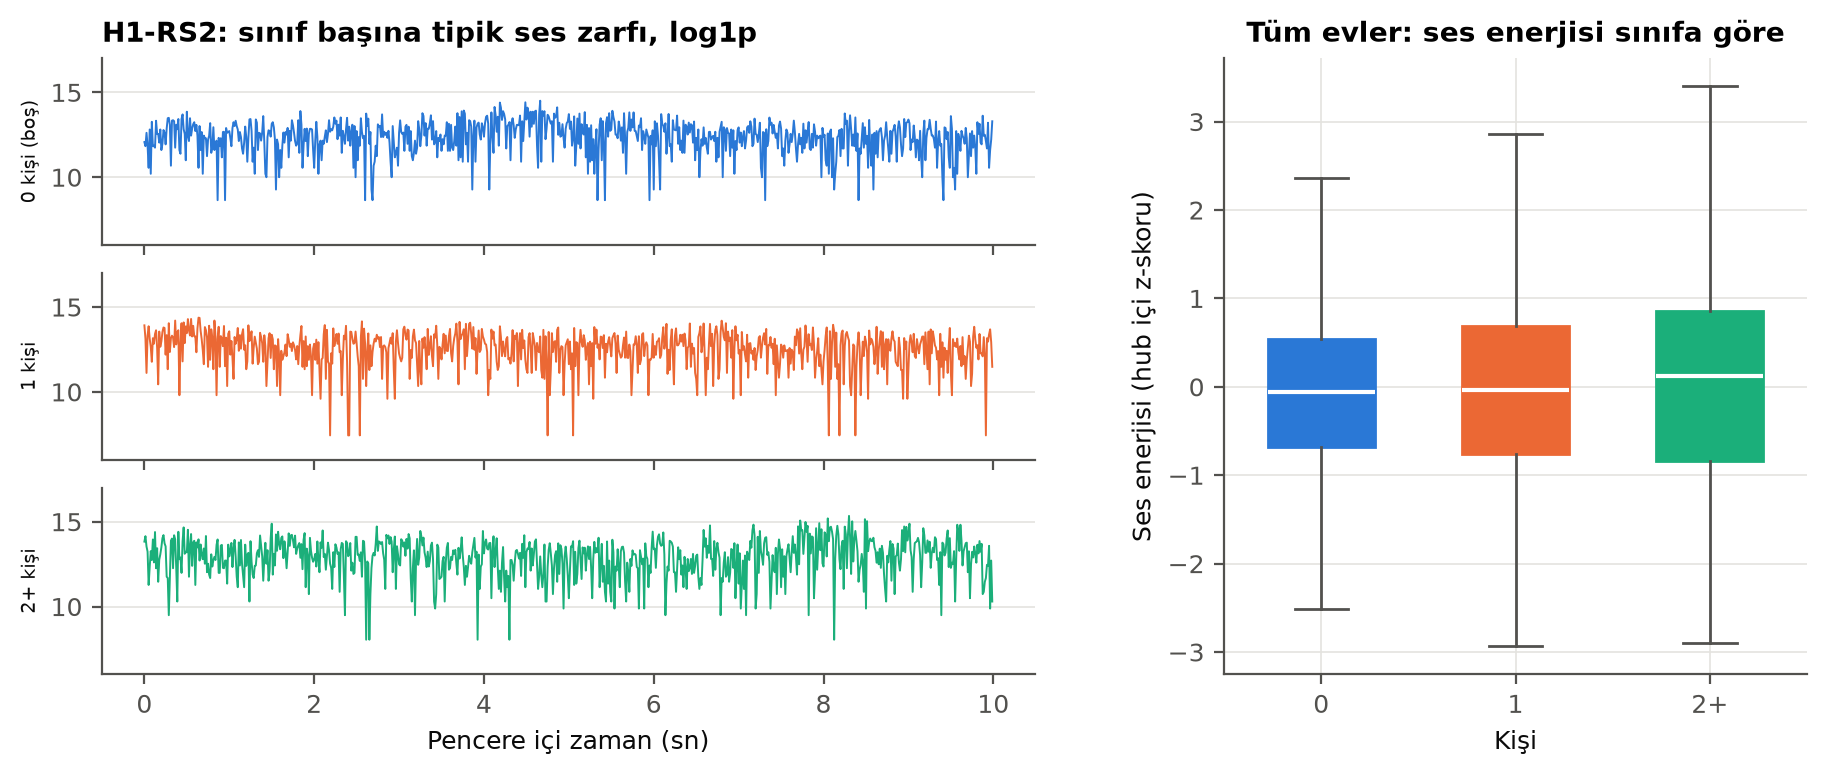

In [17]:
show("fig04_ortam_sinif.png"); show("fig10_ses_sinif.png")

In [18]:
md_file("reports/ozet_istatistik.md")

# Özet istatistikler

`python src/eda.py tab02`. Ortam değerleri temizlenmiş (aralık dışı NaN), hub'lar birleştirilmiş; NaN'lar hesaba katılmaz. n = geçerli pencere sayısı.

## TVOC (ppb)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,696,166 | 23.19 | 79.55 | 0 | 0 | 0 | 0 | 1,603 |
| 1 kişi | 2,033,400 | 20.18 | 117.50 | 0 | 0 | 0 | 0 | 11,419 |
| 2+ kişi | 2,065,914 | 22.49 | 126.65 | 0 | 0 | 0 | 0 | 12,265 |
| hepsi | 5,795,480 | 21.89 | 111.42 | 0 | 0 | 0 | 0 | 12,265 |

## Sıcaklık (°C)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,597,285 | 28.34 | 3.10 | 25.80 | 28 | 30.80 | 0 | 36.90 |
| 1 kişi | 1,917,655 | 28.77 | 3.11 | 26.20 | 28.40 | 30.90 | 0 | 40 |
| 2+ kişi | 1,950,156 | 27.65 | 2.84 | 25.20 | 27.30 | 30 | 0 | 39.70 |
| hepsi | 5,465,096 | 28.24 | 3.05 | 25.70 | 27.90 | 30.50 | 0 | 40 |

## Bağıl nem (%)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,386,932 | 21.42 | 7.74 | 15.50 | 19.30 | 25.90 | 0 | 51.60 |
| 1 kişi | 1,621,564 | 21.90 | 6.29 | 17.70 | 20.80 | 24.60 | 0 | 52.40 |
| 2+ kişi | 1,554,900 | 27.86 | 8.09 | 21.30 | 26.20 | 33.60 | 0 | 69 |
| hepsi | 4,563,396 | 23.79 | 7.95 | 18 | 22.10 | 28.30 | 0 | 69 |

## Işık (lux)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,696,024 | 2,209.73 | 6,634.81 | 24 | 519 | 1,845 | 0 | 99,472 |
| 1 kişi | 2,032,894 | 1,710.52 | 5,331.25 | 14 | 377 | 1,585 | 0 | 99,915 |
| 2+ kişi | 2,065,513 | 1,100.86 | 4,510.08 | 0 | 28 | 664 | 0 | 99,929 |
| hepsi | 5,794,431 | 1,639.32 | 5,505.23 | 6 | 234 | 1,409 | 0 | 99,929 |

## eCO2 (ppm)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,696,166 | 462.47 | 208.30 | 400 | 400 | 400 | 400 | 4,830 |
| 1 kişi | 2,033,400 | 462.60 | 373.85 | 400 | 400 | 400 | 400 | 53,995 |
| 2+ kişi | 2,065,914 | 488.13 | 524.92 | 400 | 400 | 400 | 400 | 60,000 |
| hepsi | 5,795,480 | 471.66 | 400.14 | 400 | 400 | 400 | 400 | 60,000 |

## Kare parlaklığı (0–255)

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,277,635 | 85.08 | 33.42 | 58.33 | 95.27 | 112.37 | 9.94 | 217.05 |
| 1 kişi | 1,497,752 | 83.92 | 32.07 | 61.50 | 91.13 | 109.38 | 9.93 | 223.14 |
| 2+ kişi | 1,126,074 | 71.64 | 37.16 | 38.82 | 77.29 | 102.96 | 9.94 | 229.95 |
| hepsi | 3,901,461 | 80.76 | 34.54 | 55.23 | 88.76 | 108.64 | 9.93 | 229.95 |

## Ses enerjisi, log1p

| Sınıf | n | ortalama | std | Q1 | medyan | Q3 | min | maks |
|---|---|---|---|---|---|---|---|---|
| 0 kişi (boş) | 1,475,889 | 12.61 | 0.85 | 12.04 | 12.69 | 13.22 | 9.93 | 17.87 |
| 1 kişi | 1,819,105 | 12.62 | 0.82 | 12.08 | 12.59 | 13.18 | 10.04 | 20.41 |
| 2+ kişi | 2,011,609 | 12.42 | 0.90 | 11.75 | 12.42 | 13.07 | 9.73 | 19.42 |
| hepsi | 5,306,603 | 12.54 | 0.87 | 11.95 | 12.56 | 13.16 | 9.73 | 20.41 |


### 6.2 Günün saati ↔ sınıf (yanlılık)

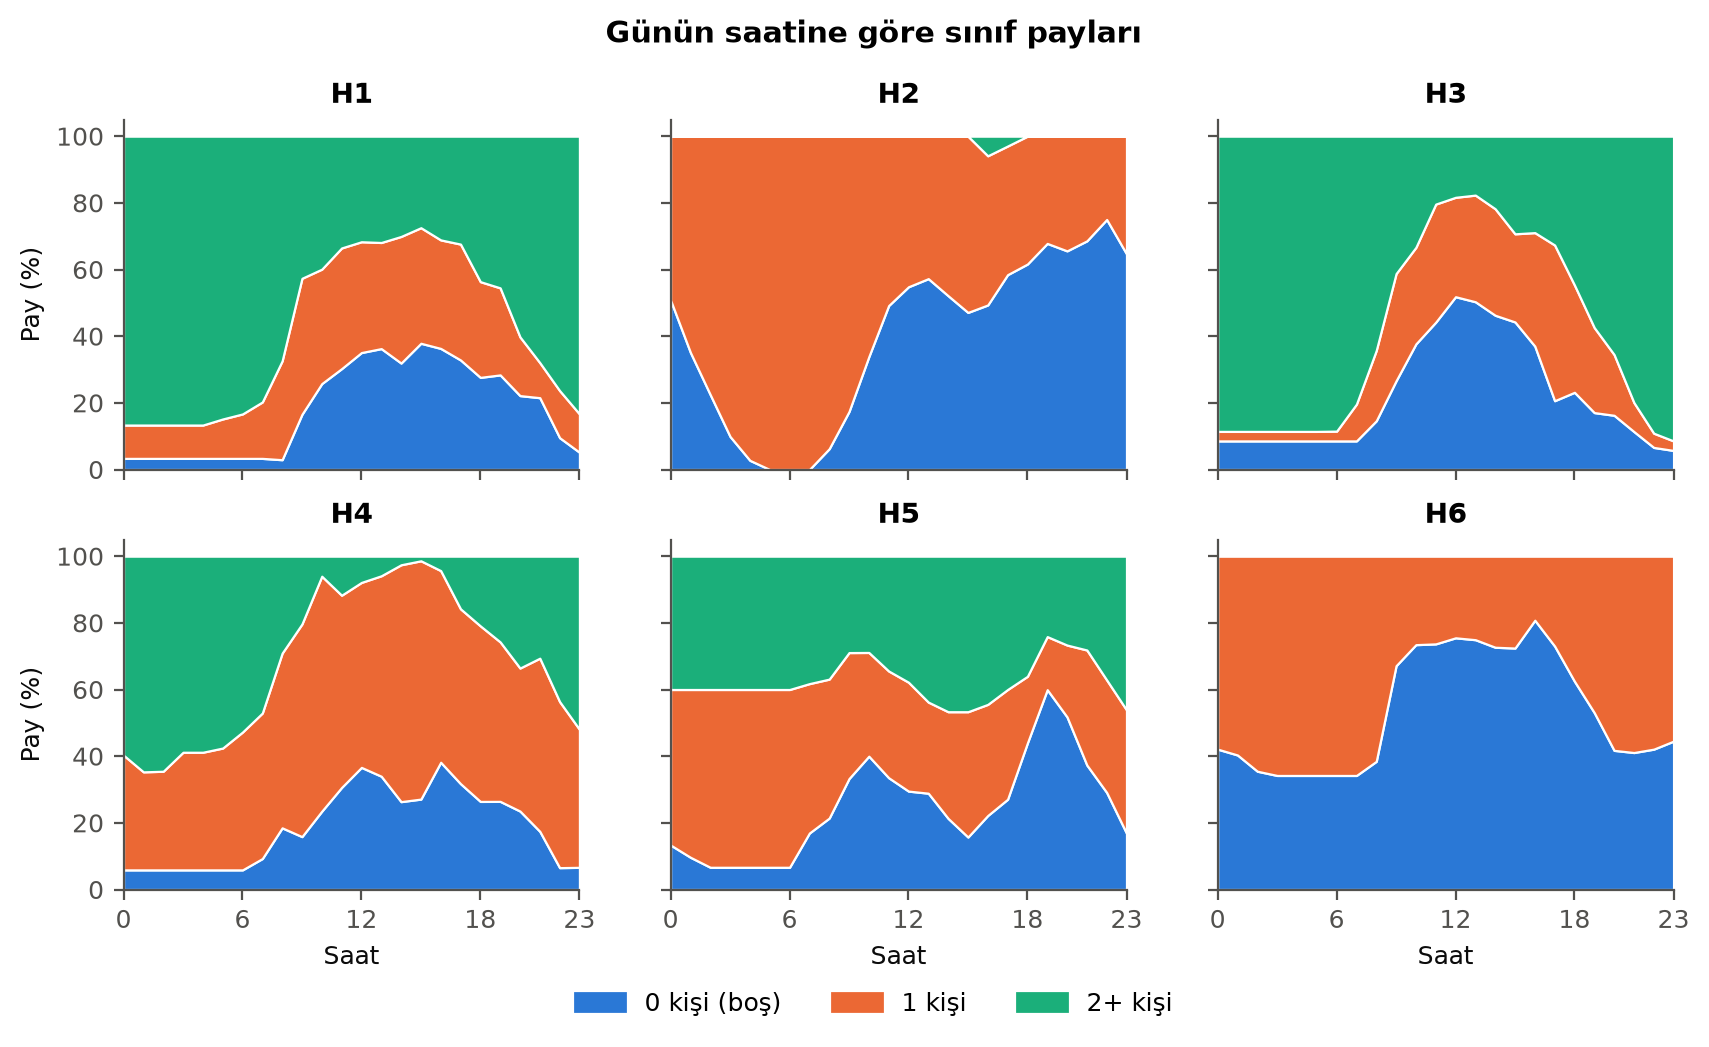

In [19]:
show("fig02_saat_sinif.png")

**Yorum:** 2+ sınıfı gece yığılıyor (H1 gece %86, öğlen %31). Model "karanlık = kalabalık" kısayolunu öğrenebilir.

### 6.3 Modaliteler arası

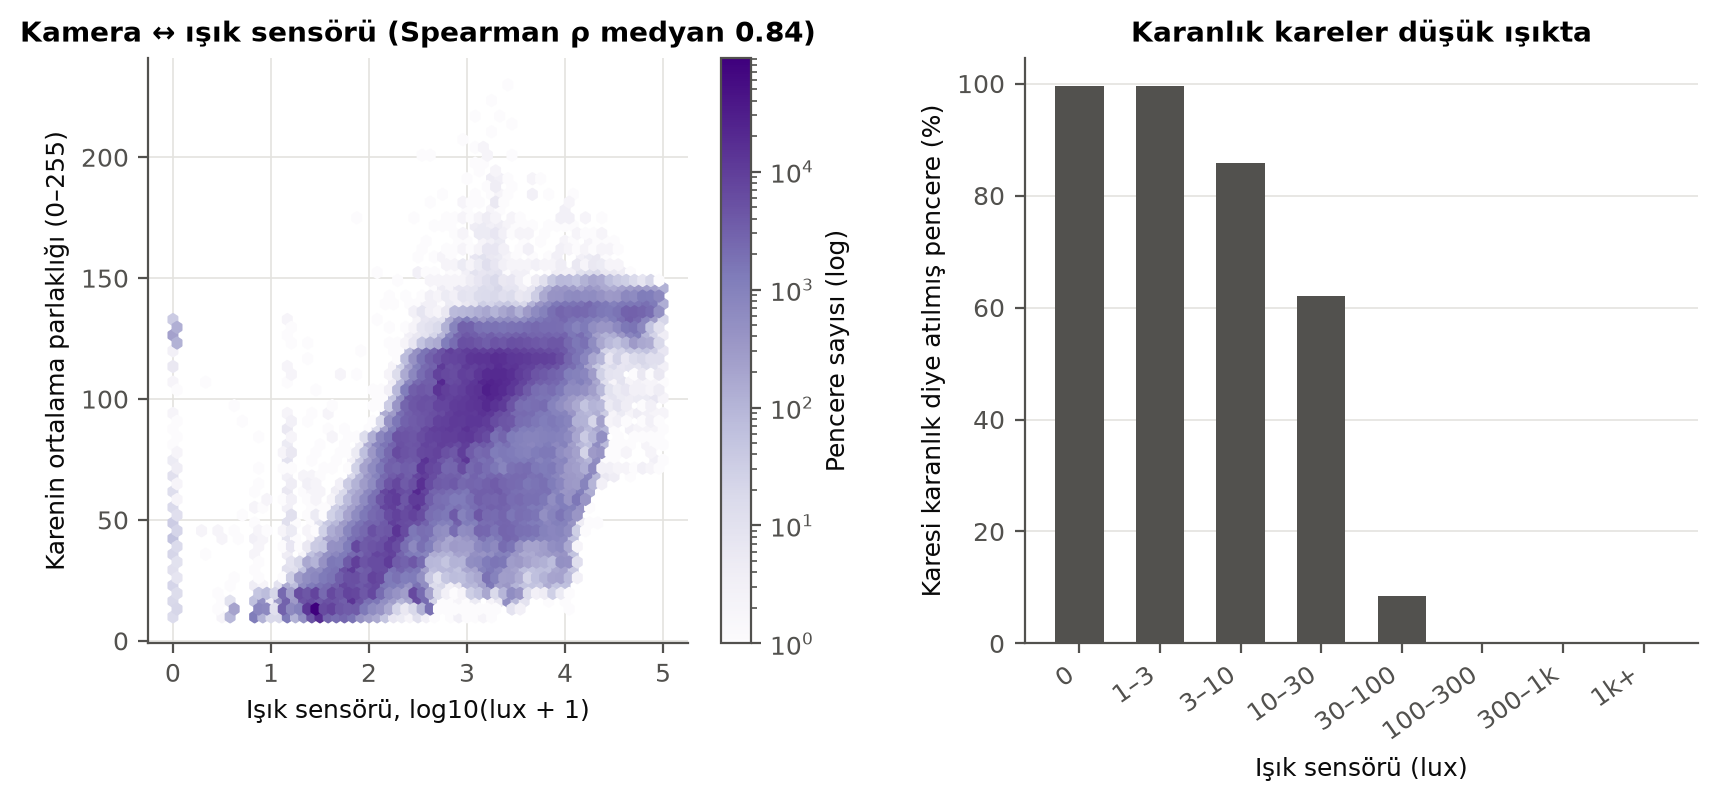

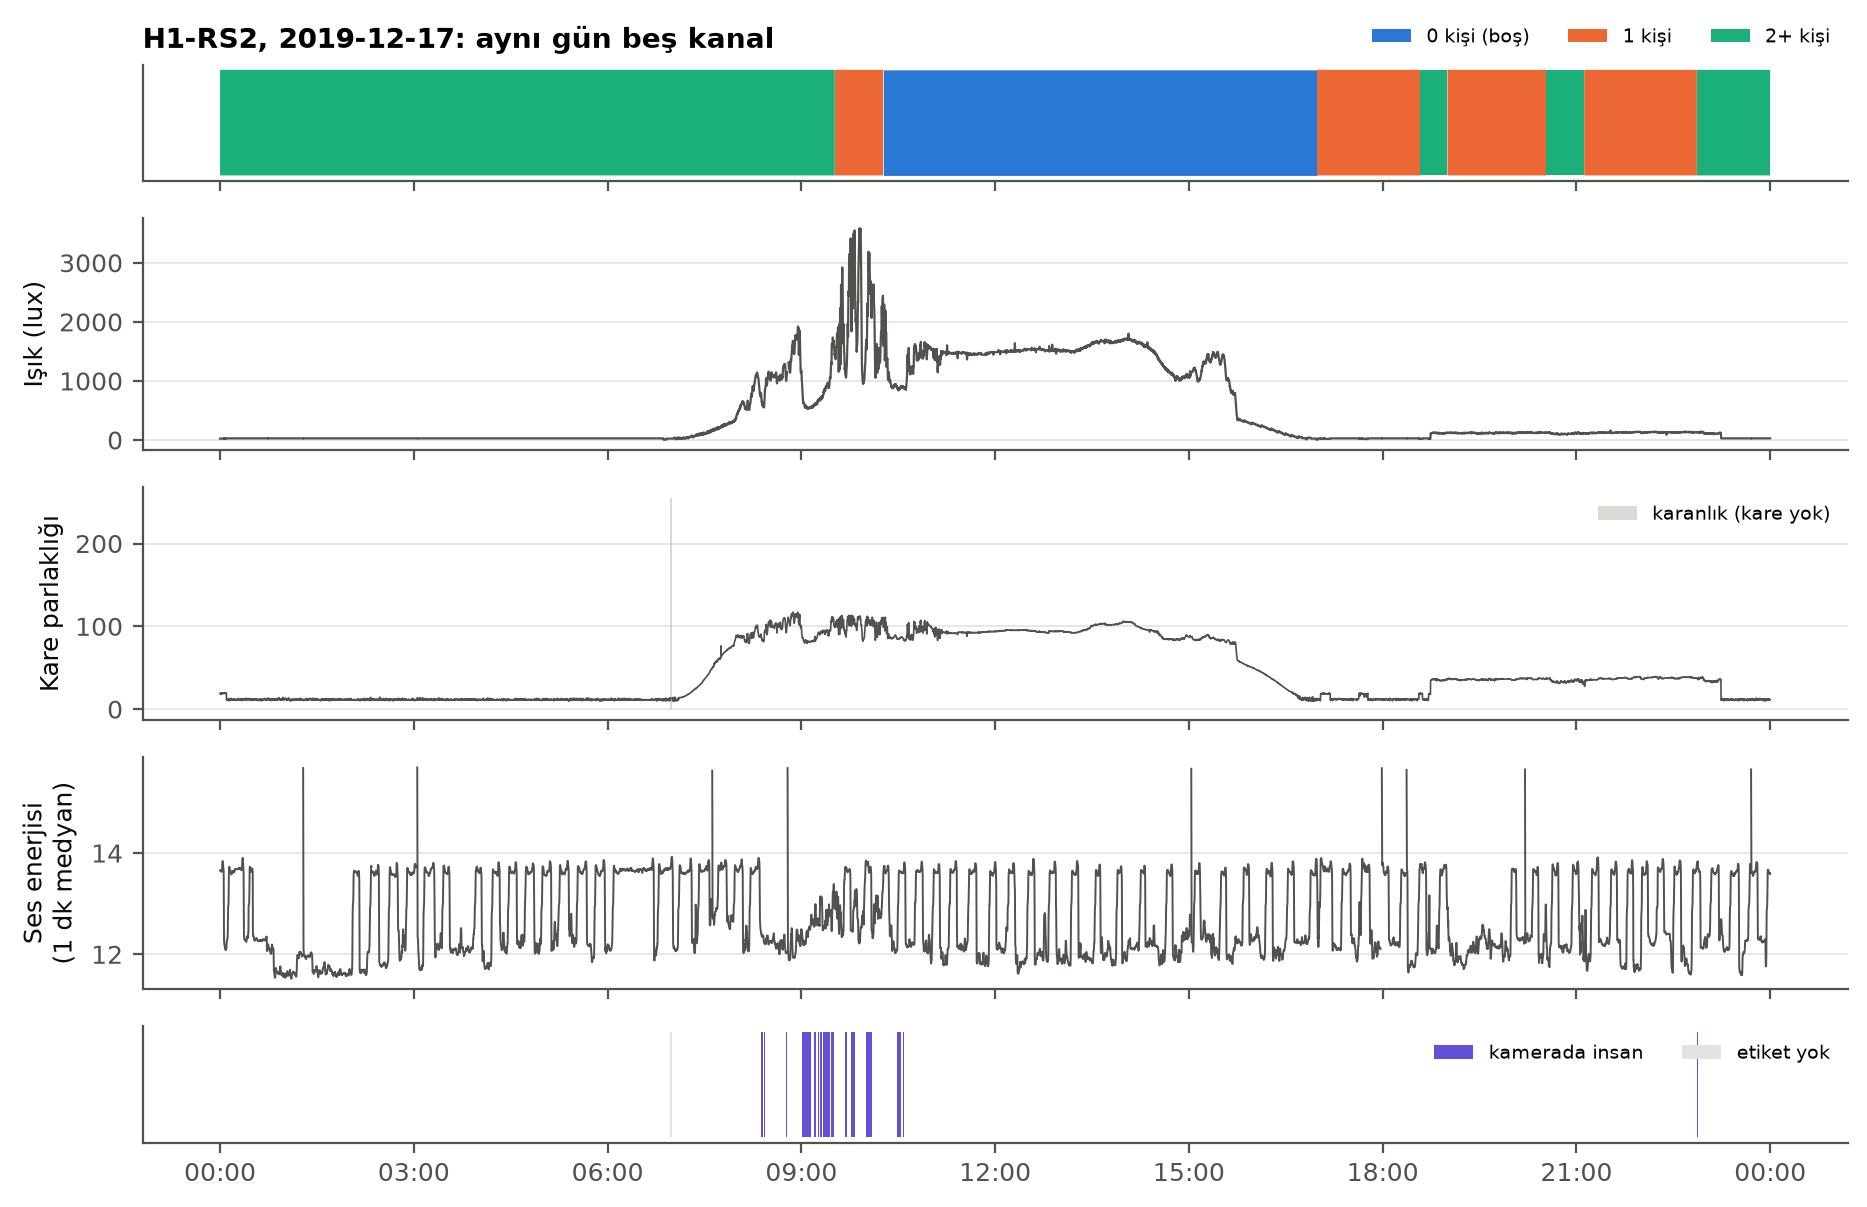

In [20]:
show("fig09_parlaklik_isik.png"); show("fig11_gun_zaman_cizgisi.png")

**Yorum:** kamera parlaklığı ile ışık sensörü aynı anda değişiyor (medyan ρ = 0,84) → hem ilişki hem de
eşleştirmenin doğruluğunun kanıtı. Seste ~20–30 dakikalık periyodik bir arka plan var.

### 6.4 Aykırı vaka: H6 BS5 kamerası

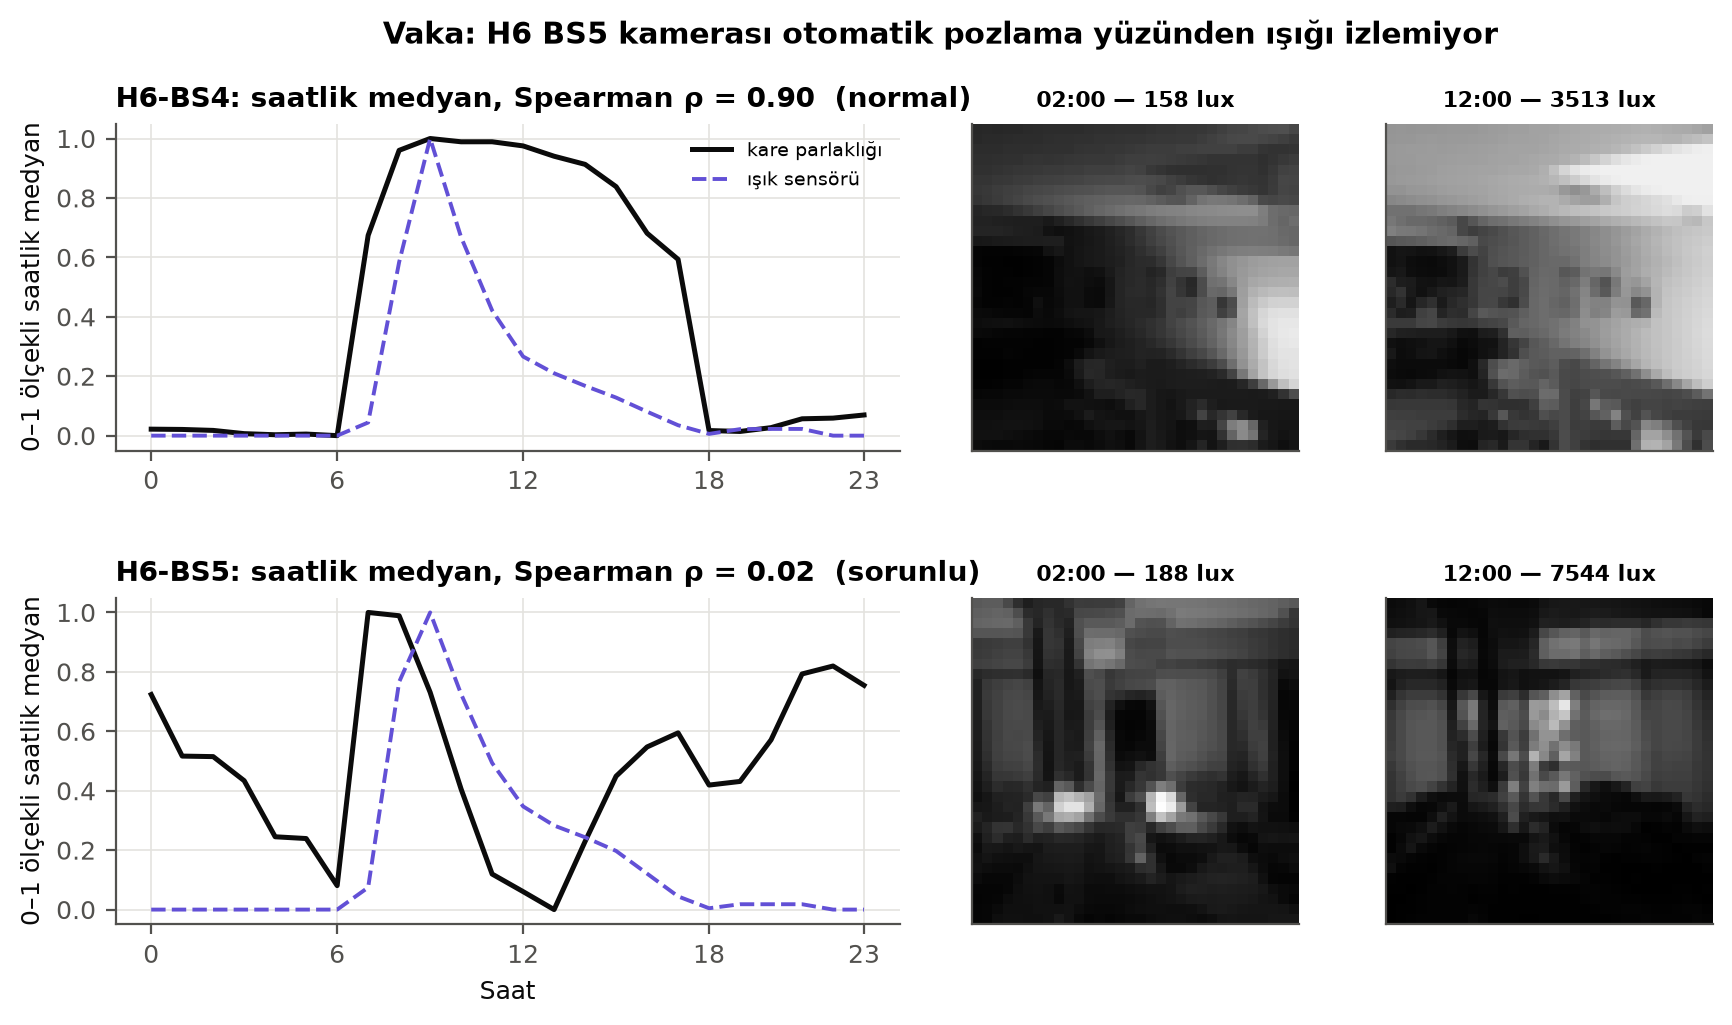

In [21]:
show("fig18_bs5_vaka.png")

**Yorum:** otomatik pozlama yüzünden bu kameranın parlaklığı ışığı izlemiyor (ρ = 0,02; normal hub 0,90).
Basit "parlaklık" özelliği yanıltıcı → modele ham kare verilecek.

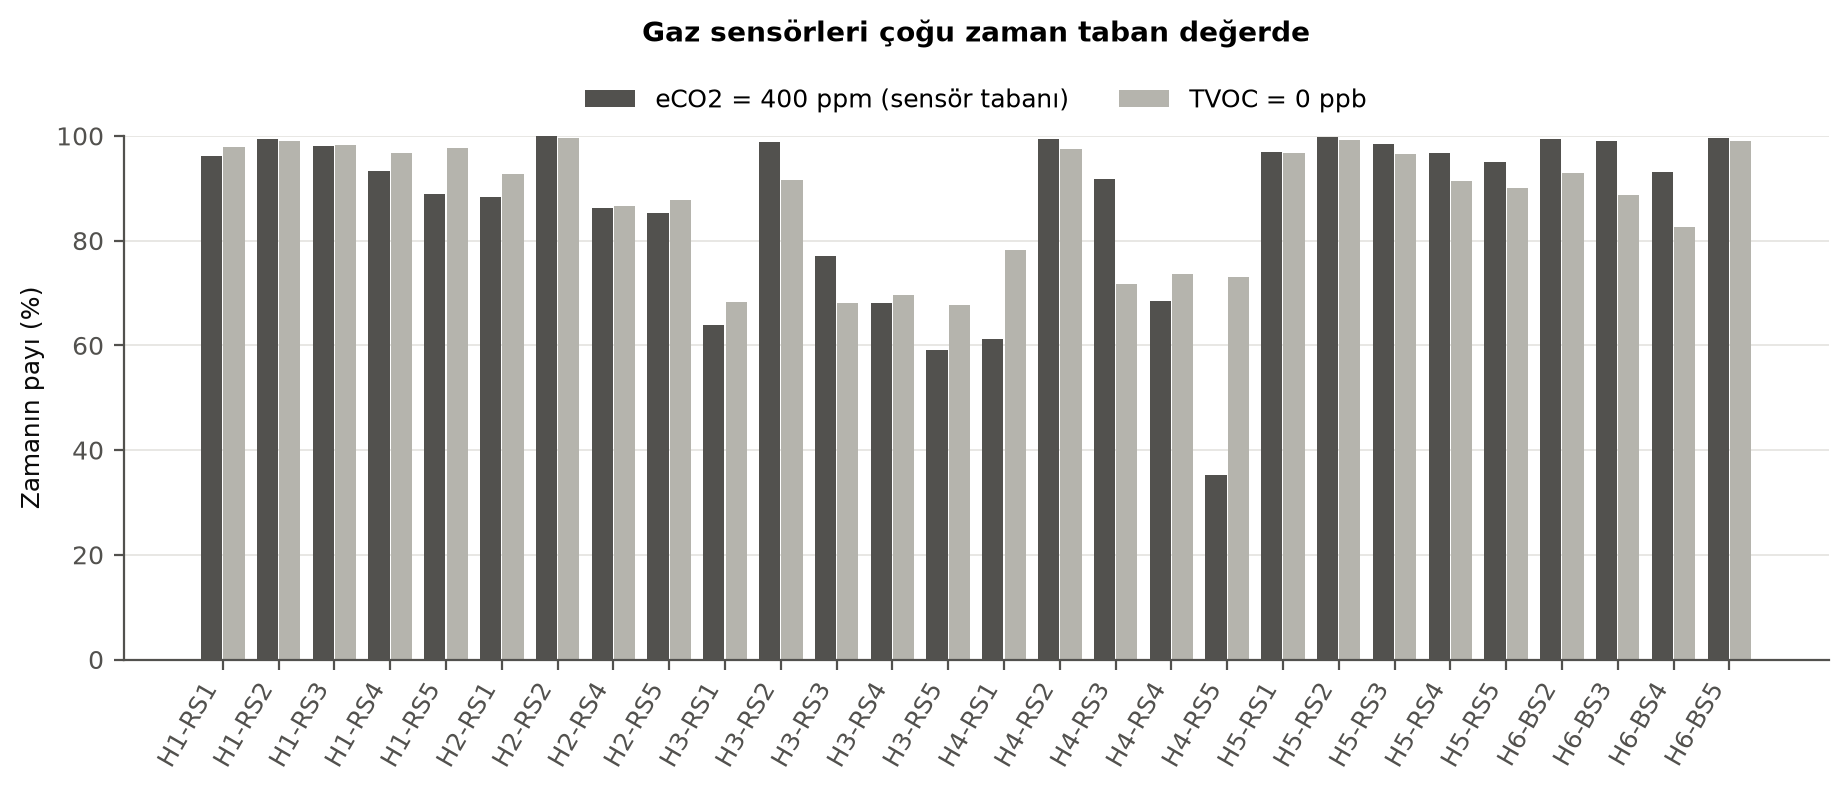

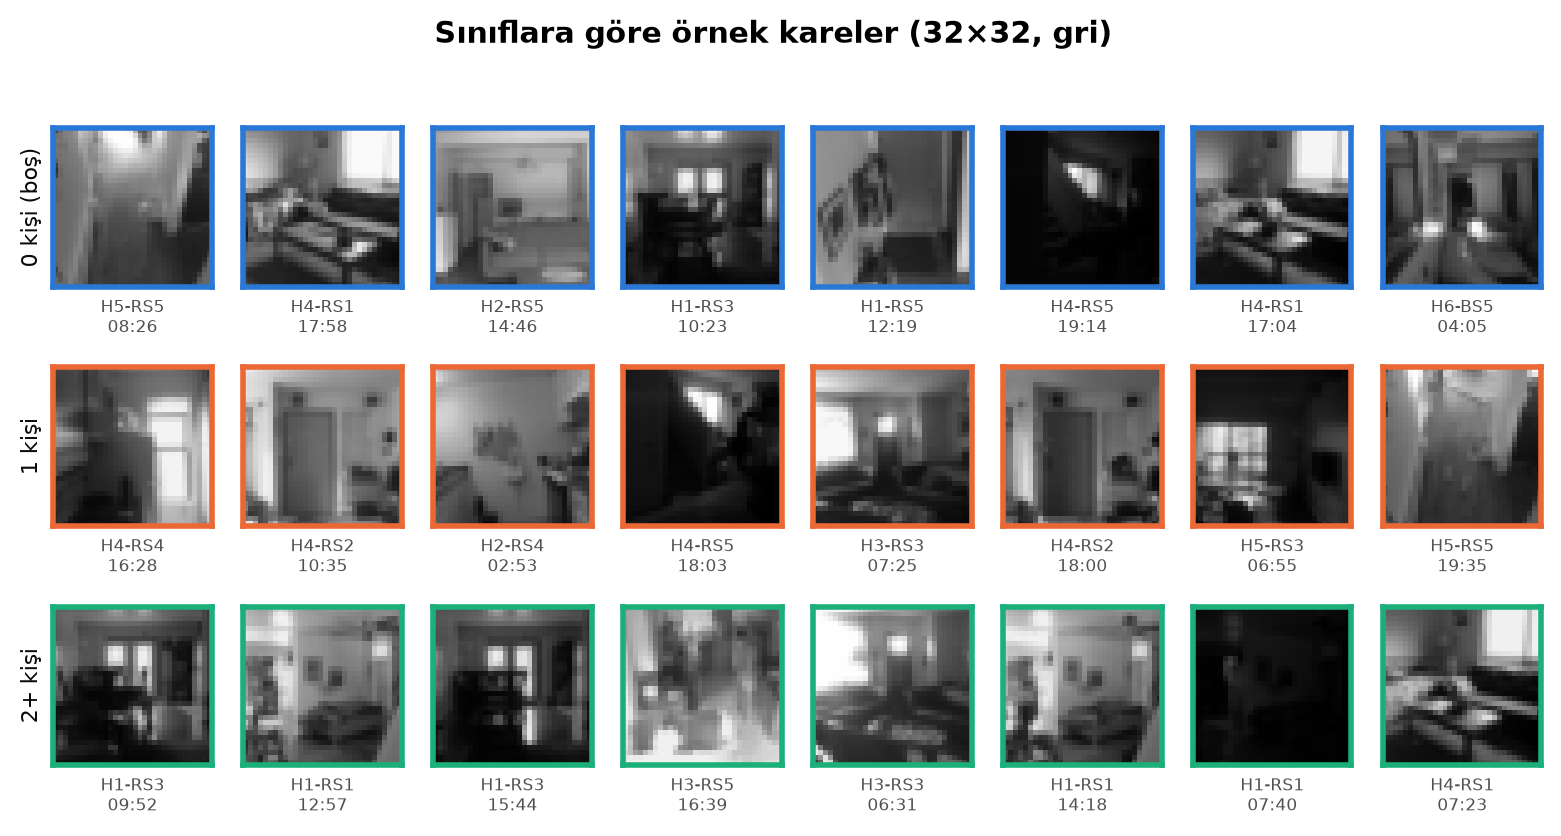

In [22]:
show("fig06_gaz_taban.png"); show("fig08_ornek_kareler.png")

## 7. Bölme planı ve modele hazır örnek (Kriter 7)

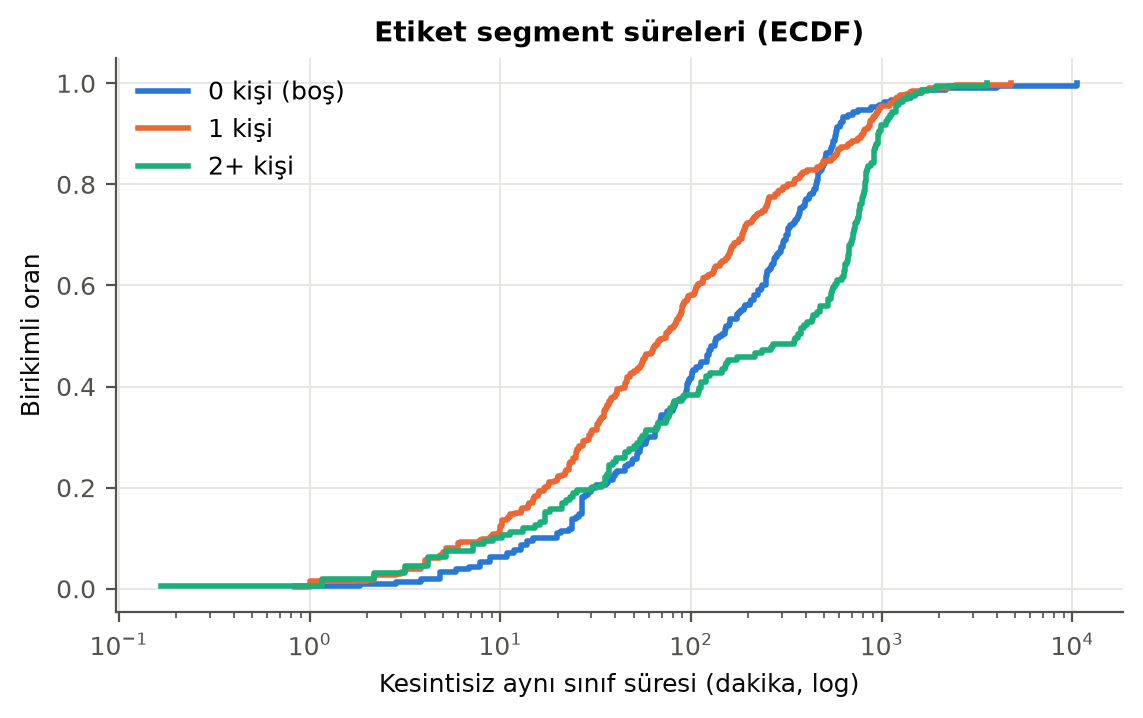

In [23]:
show("fig03_segment_sureleri.png", 600)

Art arda iki pencerenin etiketi %99,95 aynı → rastgele bölme sızıntı yapar. Çözüm: **leave-one-home-out** (6 kat)
+ her eğitim evinde zamansal doğrulama (son %20, 6 saat boşluk).

In [24]:
md_file("reports/bolme_plani.md")

# Bölme planı

`python src/split.py` ile üretilir. Gerekçe: `src/split.py` başındaki açıklama, fig03.

Sayılar = 10 sn pencere, sınıf sırası 0 / 1 / 2+. İç bölme: her eğitim evinin son %20'si doğrulama, öncesindeki 6 saat atılır (gap).

| Kat | Test evi | Eğitim (0/1/2+) | Doğrulama (0/1/2+) | Gap'te atılan | Test (0/1/2+) | Testte 2+ var mı |
|---|---|---|---|---|---|---|
| 1 | H1 | 244,351 / 326,681 / 207,864 | 107,951 / 89,376 / 67,057 | 10,800 | 45,921 / 58,866 / 153,058 | evet |
| 2 | H2 | 239,747 / 295,405 / 332,516 | 101,867 / 90,121 / 94,589 | 10,800 | 58,150 / 88,189 / 541 | yok sayılır (541, %0.4) |
| 3 | H3 | 237,452 / 328,610 / 194,470 | 94,971 / 89,220 / 54,002 | 10,800 | 65,800 / 55,632 / 180,968 | evet |
| 4 | H4 | 269,232 / 316,953 / 288,395 | 102,063 / 85,804 / 91,798 | 10,800 | 26,928 / 72,499 / 47,453 | evet |
| 5 | H5 | 258,803 / 315,870 / 306,819 | 108,857 / 108,102 / 73,074 | 10,800 | 31,606 / 49,124 / 48,870 | evet |
| 6 | H6 | 189,010 / 230,366 / 332,516 | 36,811 / 88,972 / 95,130 | 10,800 | 174,562 / 153,758 / 0 | yok sayılır (0, %0.0) |

## Kurallar

- **Sızıntı:** aynı ev hem eğitimde hem testte olmaz; doğrulama eğitimden zamanca sonra gelir ve arada 6 saat boşluk var.
- **Normalizasyon:** her hub kendi verisinin ortalama/std'si ile ölçeklenir (fig13). Etiket kullanılmaz, bu yüzden test evinin istatistiğini hesaplamak etiket sızıntısı değildir (gözetimsiz uyarlama). Katı alternatif: test evinde yalnız ilk 24 saatin istatistiği — finalde ikisi karşılaştırılacak.
- **H2 ve H6 test katları:** 2+ sınıfı yok (H2'de 541, H6'da 0). Bu katlarda 3 sınıflı macro-F1 tanımsız olur; sınıf bazında F1 ve 6 katın birleşik (pooled) karışıklık matrisi raporlanacak.
- **Sınıf dengesi:** eğitimde sınıf payları dengeli (~%30–37); ağırlıklandırma gerekirse eğitim katının sayılarından hesaplanır.
- **Eksik modalite:** pencere silinmez; her modalite için maske taşınır (fig07). Finalde eğitim sırasında rastgele modalite düşürme (modality dropout) ile eksik modaliteye dayanıklılık ölçülecek.


In [25]:
from dataset import window
w = window("H6", 100_000)     # 4 hub'lı ev: 5. yuva boş
for k in ["img", "aud", "env", "mask_img", "mask_aud", "mask_env"]:
    print(f"{k:9s} {str(w[k].shape):12s} {w[k].dtype}")
print("hub yuvaları:", w["hubs"])
print("görüntü maskesi:", w["mask_img"].astype(int), " ses maskesi:", w["mask_aud"].astype(int))
print("etiket y =", w["y"], f"(kişi sayısı {w['number']})")

img       (5, 32, 32)  float32
aud       (5, 800)     float32
env       (5, 5)       float32
mask_img  (5,)         bool
mask_aud  (5,)         bool
mask_env  (5, 5)       bool
hub yuvaları: ['BS2', 'BS3', 'BS4', 'BS5', None]
görüntü maskesi: [1 1 1 1 0]  ses maskesi: [0 1 0 1 0]
etiket y = 0 (kişi sayısı 0)


## 8. Yeniden üretim (Kriter 8)

```
.venv/bin/python src/download.py            # küçük dosyalar
.venv/bin/python src/build.py all --fetch   # büyük zip'ler: indir → işle → sil
.venv/bin/python src/eda.py                 # bütün şekil ve tablolar
.venv/bin/python src/split.py               # bölme planı (kendi testini çalıştırır)
.venv/bin/python src/dataset.py             # model veri yapısı (kendi testini çalıştırır)
```
Ayrıntı: `README.md`, rapor: `reports/rapor.md`, veri sorunları: `docs/VERI_SORUNLARI.md`.